# EDA assessment

### 1. Basic characteristics of the dataset

Completed

| Characteristic | Result |
|---|---|
| Dataset type | Structured tabular data |
| Domain | Banking and financial services |
| Observations | 1,347,681 |
| Original variables | 15 |
| Final clustering features | 24 |
| Numerical variables | Continuous and discrete |
| Categorical variables | Nominal and ordinal |
| Target information | Default (reserved for post-clustering evaluation) |

Interpretation: This is a large-scale structured financial dataset containing borrower characteristics, loan details, and historical loan outcomes.

### 2. Overall dataset structure

Completed

The original dataset contains numerical, categorical, date, identifier, and text variables.

| Variable | Type | Treatment |
|---|---|---|
| id | Identifier | Excluded |
| issue_d | Date | Preserved for temporal analysis |
| revenue | Continuous | Log-transformed |
| dti_n | Continuous | Suspicious values treated |
| loan_amnt | Continuous/discrete | Scaled |
| fico_n | Continuous | Scaled |
| experience_c | Discrete | Excluded (near-constant) |
| emp_length | Ordinal categorical | Ordinal encoded |
| purpose | Nominal categorical | One-hot encoded |
| home_ownership_n | Nominal categorical | One-hot encoded |
| addr_state | Nominal categorical | Excluded from initial clustering |
| zip_code | Identifier/geographic code | Excluded |
| Default | Binary | Reserved for risk evaluation |
| title | Text | Excluded |
| desc | Text | Excluded |

### 3. Patterns and relationships in the data

Completed

The correlation analysis revealed:

| Variable relationship | Correlation | Interpretation |
|---|---|---|
| Revenue – Loan Amount | +0.513 | Moderate positive |
| Revenue – DTI | -0.180 | Weak negative |
| Revenue – FICO | +0.108 | Weak positive |
| DTI – Loan Amount | +0.036 | Very weak positive |
| DTI – FICO | -0.078 | Very weak negative |
| Loan Amount – FICO | +0.101 | Weak positive |

Key finding: Borrowers with higher revenue tend to have somewhat larger loans, but the relationship is not strong enough to assume revenue determines loan amount.

Default rates by loan purpose, employment length, home ownership and other borrower subgroups are analysed in Sections 2 and 9.

### 4. Outlier analysis

Completed for selected numerical features

| Variable | Important finding | Treatment |
|---|---|---|
| Revenue | Maximum 10,999,200 | Log transformation |
| DTI | 535 records at or above 100; 1,410 above 65 | Capped at 65 (dti_capped); flagged at 100 or above (dti_extreme) |
| FICO | Maximum 847.5 | Retained provisionally |
| Loan amount | Range 500–40,000 | Retained |

Important: An outlier is not automatically an error. Extreme observations should be investigated before removal, especially in financial datasets where unusual borrowers may represent important risk segments.

### 5. Missing-value analysis

Completed

Original missing-value results:

| Column | Missing records | Percentage |
|---|---|---|
| desc | 1,228,582 | 91.163% |
| title | 16,657 | 1.236% |
| zip_code | 1 | Negligible |
| All other columns | 0 | 0% |

Conclusion: The description and title columns were excluded, and ZIP code was excluded from initial clustering. The selected final clustering features contain zero missing values.

### 6. Data correctness and quality

Partially completed

Checks performed:

- No duplicate rows.
- No duplicate loan IDs.
- No missing loan IDs.
- Selected feature types were checked.
- Suspicious DTI values were investigated.
- Extreme revenue and FICO observations were examined.

One limitation: duplicate checks and internal consistency checks do not prove the authenticity of the dataset's original source. We still need to verify its source documentation, collection period, field definitions, and any transformations already applied to the data.

### 7. Correlation between variables

Completed for numerical features

The Pearson correlation analysis was performed on revenue, DTI, loan amount, and FICO score.

The strongest observed relationship was revenue versus loan amount (+0.513). Coefficients use log-transformed revenue and capped DTI (see Section 7).

Conclusion: There are no very strong linear correlations among these four numerical features. However, correlation alone cannot identify nonlinear relationships or categorical associations.

### 8. Comparison with past performance

Partially completed

This is particularly important for a loan portfolio.

Completed in Section 5: loan volumes, average loan amount and default rate by issue year.

Still pending:

- Average revenue and DTI by year.
- Changes in borrower credit scores over time.

In [1]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path(
    r"D:\HCL_PROJECTS\Credit Portfolio Segmentation and Risk Pattern Analysis Project-3\step2_outputs\cleaned_credit_portfolio.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1347681, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,Default,revenue_log,dti_capped,dti_extreme
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,0,10.915107,5.91,0
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,0,11.082158,16.06,0
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,0,11.170449,13.85,0
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,0,11.556311,25.37,0
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,0,10.434145,10.20,0


In [2]:
# 1. Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# 2. Column names
print(df.columns.tolist())

# 3. Data types
df.info()

# 4. Missing values
display(df.isnull().sum())

# 5. Duplicate records
print("Duplicate rows:", df.duplicated().sum())

# 6. Statistical summary
display(df.describe(include="all").T)

Rows: 1347681
Columns: 15
['id', 'issue_d', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'Default', 'revenue_log', 'dti_capped', 'dti_extreme']
<class 'pandas.DataFrame'>
RangeIndex: 1347681 entries, 0 to 1347680
Data columns (total 15 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1347681 non-null  int64  
 1   issue_d           1347681 non-null  str    
 2   revenue           1347681 non-null  float64
 3   dti_n             1347681 non-null  float64
 4   loan_amnt         1347681 non-null  int64  
 5   fico_n            1347681 non-null  float64
 6   experience_c      1347681 non-null  int64  
 7   emp_length        1347681 non-null  str    
 8   purpose           1347681 non-null  str    
 9   home_ownership_n  1347681 non-null  str    
 10  addr_state        1347681 non-null  str    
 11  Default           1347681 non-null  int

id                  0
issue_d             0
revenue             0
dti_n               0
loan_amnt           0
fico_n              0
experience_c        0
emp_length          0
purpose             0
home_ownership_n    0
addr_state          0
Default             0
revenue_log         0
dti_capped          0
dti_extreme         0
dtype: int64

Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,1347681.0,NaN,NaN,NaN,56213593.228885,38395009.681332,54734.0,19706506.0,57664225.0,84495046.0,145636374.0
issue_d,1347681,139,Mar-2016,48927,NaN,NaN,NaN,NaN,NaN,NaN,NaN
revenue,1347681.0,NaN,NaN,NaN,77369.683174,70362.989597,1896.0,46600.0,65000.0,92000.0,10999200.0
dti_n,1347681.0,NaN,NaN,NaN,18.299091,11.152139,0.0,11.82,17.63,24.07,999.0
loan_amnt,1347681.0,NaN,NaN,NaN,14408.23049,8715.347372,500.0,7975.0,12000.0,20000.0,40000.0
fico_n,1347681.0,NaN,NaN,NaN,698.158922,31.848725,612.0,672.0,692.0,712.0,847.5
experience_c,1347681.0,NaN,NaN,NaN,0.999981,0.004307,0.0,1.0,1.0,1.0,1.0
emp_length,1347681,12,10+ years,442667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purpose,1347681,14,debt_consolidation,781206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
home_ownership_n,1347681,4,MORTGAGE,666594,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.1 Portfolio summary

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

portfolio_summary = {
    'Total Loans': df['id'].nunique(),
    'Total Loan Amount': df['loan_amnt'].sum(),
    'Average Loan Amount': df['loan_amnt'].mean(),
    'Median Loan Amount': df['loan_amnt'].median(),
    'Average Revenue': df['revenue'].mean(),
    'Median Revenue': df['revenue'].median(),
    'Average FICO Score': df['fico_n'].mean(),
    'Average DTI': df['dti_n'].mean(),
    'Total Defaults': df['Default'].sum(),
    'Default Rate (%)': df['Default'].mean() * 100
}

summary_df = pd.DataFrame(
    portfolio_summary.items(),
    columns=['Metric', 'Value']
)

print(summary_df.to_string(index=False))

             Metric        Value
        Total Loans 1.347681e+06
  Total Loan Amount 1.941770e+10
Average Loan Amount 1.440823e+04
 Median Loan Amount 1.200000e+04
    Average Revenue 7.736968e+04
     Median Revenue 6.500000e+04
 Average FICO Score 6.981589e+02
        Average DTI 1.829909e+01
     Total Defaults 2.692490e+05
   Default Rate (%) 1.997869e+01


The credit portfolio consists of 1,347,681 loan records with a total loan value of approximately \$19.42 billion. The average loan amount is \$14,408, while the median loan amount is \$12,000, indicating a potential right-skewed distribution. Borrowers have an average annual revenue of approximately \$77,370, an average FICO score of 698, and an average debt-to-income ratio of 18.30. The overall default rate is approximately 19.98%, indicating that nearly one-fifth of the loans are classified as defaults. These findings establish the baseline portfolio characteristics for further borrower segmentation and credit risk analysis.

### 1.2 Loan portfolio distribution

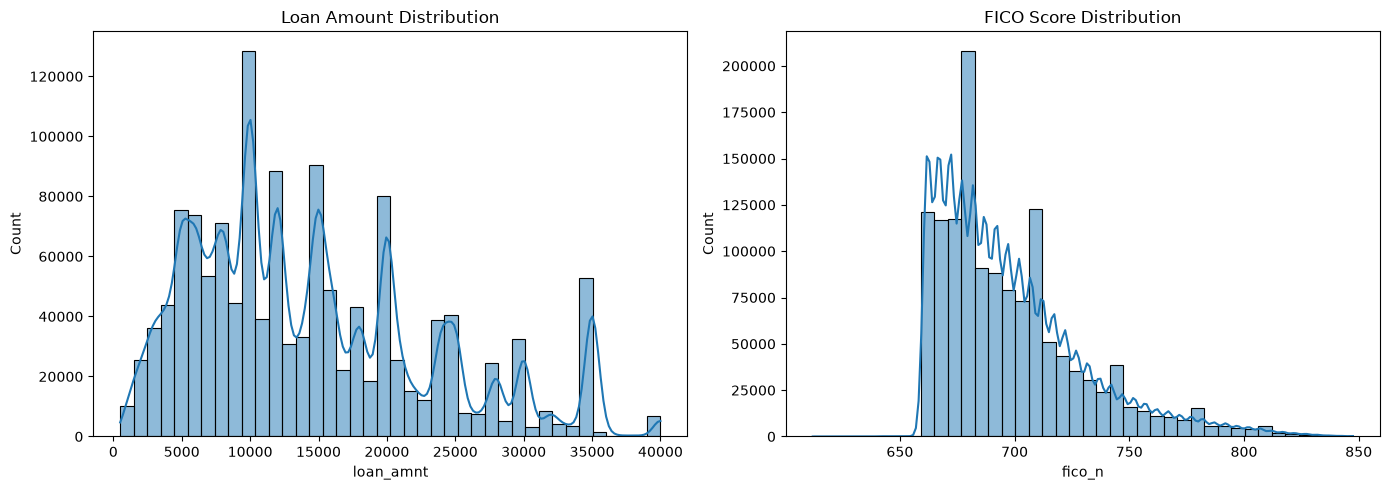

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['loan_amnt'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Loan Amount Distribution')

sns.histplot(df['fico_n'], bins=40, kde=True, ax=axes[1])
axes[1].set_title('FICO Score Distribution')

plt.tight_layout()
plt.show()

### 1.3 Overall default distribution

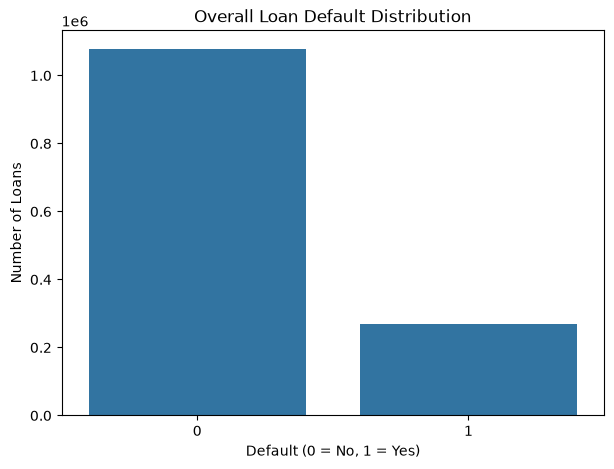

In [7]:
default_counts = df['Default'].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=default_counts.index,
    y=default_counts.values
)

plt.title('Overall Loan Default Distribution')
plt.xlabel('Default (0 = No, 1 = Yes)')
plt.ylabel('Number of Loans')
plt.show()

### 1.4 Monthly loan issuance

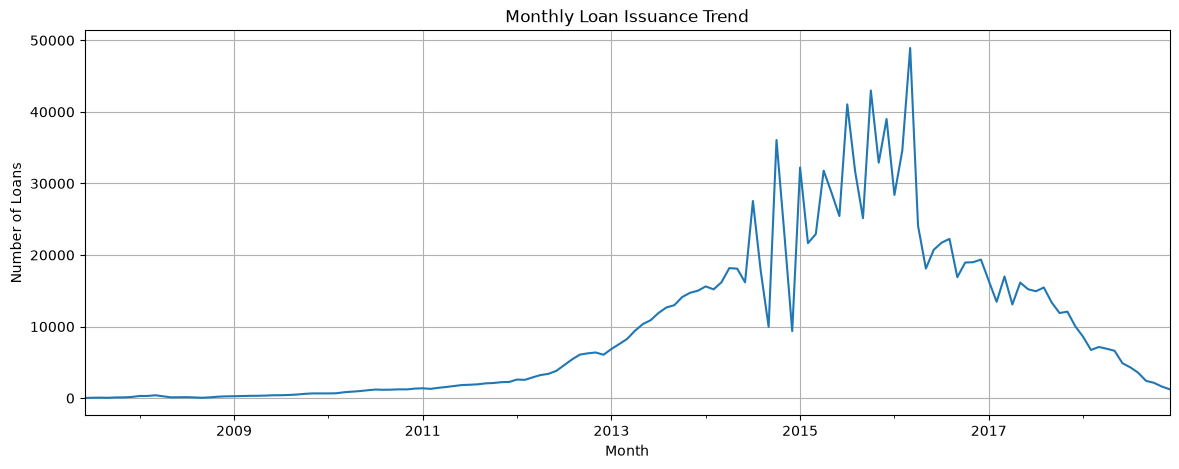

In [8]:
df['issue_d'] = pd.to_datetime(
    df['issue_d'],
    format='%b-%Y'
)

monthly_loans = (
    df.groupby(df['issue_d'].dt.to_period('M'))
      .size()
)

monthly_loans.plot(figsize=(14, 5))

plt.title('Monthly Loan Issuance Trend')
plt.xlabel('Month')
plt.ylabel('Number of Loans')
plt.grid()
plt.show()

### 1.5 Distribution analysis (without graphs)

In [9]:
# Distribution statistics
cols = [
    'loan_amnt',
    'revenue_log',
    'fico_n',
    'dti_capped'
]

for col in cols:
    print(f"\n--- {col} ---")

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Std:", df[col].std())
    print("Skewness:", df[col].skew())
    print("25%:", df[col].quantile(0.25))
    print("75%:", df[col].quantile(0.75))


--- loan_amnt ---
Mean: 14408.230490004682
Median: 12000.0
Std: 8715.347371758873
Skewness: 0.783200077220864
25%: 7975.0
75%: 20000.0

--- revenue_log ---
Mean: 11.09949144978489
Median: 11.082157933374816
Std: 0.5383695463164622
Skewness: 0.21113413813725293
25%: 10.74937727911096
75%: 11.429554725537322

--- fico_n ---
Mean: 698.1589222523728
Median: 692.0
Std: 31.848724860767923
Skewness: 1.284511654331528
25%: 672.0
75%: 712.0

--- dti_capped ---
Mean: 18.21147491876787
Median: 17.63
Std: 8.669437204965773
Skewness: 0.47220442147680075
25%: 11.82
75%: 24.07


### 1.6 Monthly loan portfolio trend

In [10]:
df['issue_d'] = pd.to_datetime(
    df['issue_d'],
    format='%b-%Y'
)

monthly_analysis = df.groupby(
    df['issue_d'].dt.to_period('M')
).agg(
    Total_Loans=('id', 'count'),
    Total_Loan_Amount=('loan_amnt', 'sum'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Default_Rate=('Default', 'mean')
)

monthly_analysis['Default_Rate'] *= 100

print(monthly_analysis.describe())
print("\nFirst 10 months:")
print(monthly_analysis.head(10))

print("\nLast 10 months:")
print(monthly_analysis.tail(10))

        Total_Loans  Total_Loan_Amount  Average_Loan_Amount  Default_Rate
count    139.000000       1.390000e+02           139.000000    139.000000
mean    9695.546763       1.396957e+08         12529.127113     17.748619
std    11012.477137       1.615866e+08          2725.828057      5.051492
min       23.000000       8.535000e+04          3710.869565      1.044177
25%      950.500000       1.005936e+07         10561.933142     14.773242
50%     5419.000000       7.257095e+07         13932.600950     17.213115
75%    15878.500000       2.305828e+08         14553.391549     20.700632
max    48927.000000       7.198691e+08         15893.582198     32.380952

First 10 months:
         Total_Loans  Total_Loan_Amount  Average_Loan_Amount  Default_Rate
issue_d                                                                   
2007-06           23              85350          3710.869565     13.043478
2007-07           62             341625          5510.080645     11.290323
2007-08         

## Section 1 – Credit Portfolio Overview: Interpretation

### 1.5 Distribution analysis

| Variable | Key observation | Interpretation |
|---|---|---|
| loan_amnt | Mean = \$14,408; median = \$12,000; skewness = 0.78 | Moderately right-skewed. A smaller number of large loans pull the average upward. |
| revenue_log | Mean = 11.10; median = 11.08; skewness = 0.21 | Approximately symmetric after log transformation. The transformation has reduced revenue skewness. |
| fico_n | Mean = 698.16; median = 692; skewness = 1.28 | Positively skewed. Some borrowers have relatively high FICO scores, pulling the mean above the median. |
| dti_capped | Mean = 18.21; median = 17.63; skewness = 0.47 | Mildly right-skewed. Most borrowers have moderate DTI, with some higher-DTI borrowers. |

Important observations:

1. Loan amounts are not normally distributed; the median is a better representation of the typical loan than the mean.
2. revenue_log is reasonably symmetric, suggesting the log transformation is useful.
3. FICO scores show positive skewness. Default rates by FICO group are examined in Section 2.
4. DTI remains moderately right-skewed even after capping.

### 1.6 Monthly loan portfolio trend

The dataset contains 139 monthly cohorts, from June 2007 to December 2018.

#### A. Loan volume

- Maximum monthly loans: 48,927 in March 2016.
- Minimum monthly loans: 23 in June 2007.
- The portfolio expanded substantially over the years.
- Loan volume declined toward the end of 2018.

#### B. Average loan amount

- Lowest monthly average: approximately \$3,711 in June 2007.
- Highest monthly average: approximately \$15,894.
- Recent months generally have average loan amounts around \$14,000–\$15,200.

This suggests that the portfolio's average loan size increased considerably compared with its earliest months.

#### C. Monthly default rate

- Highest observed monthly default rate: 32.38% in October 2007.
- Lowest observed monthly default rate: 1.04% in December 2018.
- The first few months have relatively high and volatile default rates.
- The final months show a sharp decline.

Important analytical caution

The declining default rate in late 2018 should not automatically be interpreted as improving credit quality. Recent loans may not have had enough time to mature and experience defaults. This is called the loan seasoning or observation-window effect.

For a fair comparison, we should eventually compare loans with similar ages or use a fixed observation window.

## Section 1 conclusion – Portfolio overview

Report-ready summary:

The credit portfolio consists of approximately 1.35 million loans issued between June 2007 and December 2018, with a total loan amount of approximately \$19.42 billion. The average loan amount is \$14,408, while the median is \$12,000, indicating a moderately right-skewed loan distribution. Borrowers have an average FICO score of approximately 698 and an average DTI of 18.30%. The overall default rate is approximately 19.98%. Monthly loan originations increased substantially over the observation period, while monthly default rates varied considerably. The unusually low default rates in recent cohorts require further investigation because recent loans may not have had sufficient time to mature.

## Section 2 – Borrower Segmentation

Objective: Understand the characteristics of different borrower groups and identify which groups have higher default rates.

The analysis covers:

1. Employment length
2. Loan purpose
3. Home ownership
4. Annual revenue groups
5. FICO score groups
6. DTI groups

### Categorical borrower segmentation

In [11]:
categorical_cols = [
    'emp_length',
    'purpose',
    'home_ownership_n'
]

for col in categorical_cols:

    print(f"\n========== {col} ==========")

    summary = df.groupby(col).agg(
        Total_Loans=('id', 'count'),
        Average_Loan_Amount=('loan_amnt', 'mean'),
        Total_Loan_Amount=('loan_amnt', 'sum'),
        Default_Count=('Default', 'sum'),
        Default_Rate=('Default', 'mean')
    )

    summary['Default_Rate'] *= 100

    summary = summary.sort_values(
        'Default_Rate',
        ascending=False
    )

    print(summary.round(2))


========== emp_length ==========
            Total_Loans  Average_Loan_Amount  Total_Loan_Amount  \
emp_length                                                        
NI                78188             11467.58          896627375   
1 year            88841             13451.58         1195051525   
< 1 year         108517             13769.94         1494272050   
3 years          107862             13861.99         1495181475   
8 years           60808             14714.82          894778825   
9 years           51019             14826.13          756414275   
2 years          122091             13745.45         1678195875   
4 years           80761             14003.75         1130956625   
5 years           84326             14144.52         1192750625   
7 years           59724             14539.71          868369450   
6 years           62877             14324.48          900680350   
10+ years        442667             15619.91         6914420025   

            Default_Count  

### Numerical borrower segmentation

In [12]:
# Revenue groups
df['revenue_group'] = pd.qcut(
    df['revenue'],
    q=5,
    duplicates='drop'
)

# FICO score groups
df['fico_group'] = pd.cut(
    df['fico_n'],
    bins=[0, 650, 680, 720, 760, 900],
    labels=[
        'Very Low',
        'Low',
        'Medium',
        'High',
        'Very High'
    ],
    right=False
)

# DTI groups
df['dti_group'] = pd.cut(
    df['dti_capped'],
    bins=[-0.01, 10, 20, 30, 40, 65],
    labels=[
        '0-10',
        '10-20',
        '20-30',
        '30-40',
        '40-65'
    ]
)

numerical_groups = [
    'revenue_group',
    'fico_group',
    'dti_group'
]

for col in numerical_groups:

    print(f"\n========== {col} ==========")

    summary = df.groupby(
        col,
        observed=True
    ).agg(
        Total_Loans=('id', 'count'),
        Average_Loan_Amount=('loan_amnt', 'mean'),
        Default_Count=('Default', 'sum'),
        Default_Rate=('Default', 'mean')
    )

    summary['Default_Rate'] *= 100

    print(summary.round(2))


========== revenue_group ==========
                        Total_Loans  Average_Loan_Amount  Default_Count  \
revenue_group                                                             
(1895.999, 42675.0]          269539              8282.19          62863   
(42675.0, 58000.0]           275302             11700.44          59162   
(58000.0, 75000.0]           287061             14311.72          58412   
(75000.0, 100000.0]          253569             17153.94          46839   
(100000.0, 10999200.0]       262210             20998.92          41973   

                        Default_Rate  
revenue_group                         
(1895.999, 42675.0]            23.32  
(42675.0, 58000.0]             21.49  
(58000.0, 75000.0]             20.35  
(75000.0, 100000.0]            18.47  
(100000.0, 10999200.0]         16.01  

========== fico_group ==========
            Total_Loans  Average_Loan_Amount  Default_Count  Default_Rate
fico_group                                              

## Section 2 – Borrower Segmentation: Interpretation

The results show several clear relationships between borrower characteristics and default risk. The strongest patterns are:

- Higher revenue is associated with lower default rates.
- Higher FICO scores are associated with lower default rates.
- Higher DTI is associated with higher default rates.
- Renters and borrowers with undisclosed employment length have higher default rates.
- Small-business-purpose loans have a particularly high default rate.

### 2.1 Employment length

| Employment length | Loans | Default rate |
|---|---|---|
| Not available (NI) | 78,188 | 26.96% |
| Less than 1 year | 108,517 | 20.54% |
| 1 year | 88,841 | 20.59% |
| 2 years | 122,091 | 19.82% |
| 3 years | 107,862 | 19.99% |
| 5 years | 84,326 | 19.62% |
| 10+ years | 442,667 | 18.80% |

Interpretation:

1. Borrowers with 10+ years of employment have the lowest default rate among the major employment categories.
2. Borrowers with unavailable employment information have a substantially higher default rate (26.96%).
3. The default rate generally declines with longer employment, although the pattern is not perfectly monotonic.

Business insight: Employment stability may be a useful indicator of credit risk. Missing employment information may also be associated with higher risk, but it should not automatically be treated as proof of instability.

### 2.2 Loan purpose

| Loan purpose | Loans | Default rate |
|---|---|---|
| Small business | 15,575 | 29.86% |
| Renewable energy | 936 | 23.72% |
| Moving | 9,520 | 23.41% |
| House | 7,294 | 21.91% |
| Medical | 15,606 | 21.84% |
| Debt consolidation | 781,206 | 21.15% |
| Other | 78,263 | 21.08% |
| Major purchase | 29,543 | 18.60% |
| Home improvement | 87,684 | 17.76% |
| Credit card | 295,551 | 16.93% |
| Car | 14,647 | 14.70% |
| Wedding | 2,350 | 12.43% |

Interpretation:

- Small-business loans have the highest default rate at 29.86%.
- Wedding loans have the lowest rate at 12.43%.
- Debt consolidation accounts for the largest number of loans and defaults because it represents a very large share of the portfolio.
- Credit-card loans also represent a substantial portfolio segment, but their default rate is below the overall portfolio rate.

Business insight: Small-business-purpose loans may need closer underwriting review and monitoring. However, the wedding category has a relatively small sample, so its low default rate should be interpreted cautiously.

### 2.3 Home ownership

| Home ownership | Loans | Default rate |
|---|---|---|
| Rent | 535,585 | 23.23% |
| Own | 144,985 | 20.63% |
| Other | 517 | 19.73% |
| Mortgage | 666,594 | 17.23% |

Interpretation:

- Renters have a higher default rate than mortgage holders.
- Mortgage holders have the lowest default rate among the major categories.
- Mortgage borrowers also have a higher average loan amount (\$15,965) than renters (\$12,625).

Business insight: Home-ownership status may help distinguish borrower segments, but it should not be used alone to decide creditworthiness. Income, DTI, FICO, and other relevant factors should be considered together.

### 2.4 Annual revenue segmentation

| Revenue group | Loans | Default rate |
|---|---|---|
| Up to \$42,675 | 269,539 | 23.32% |
| \$42,675–\$58,000 | 275,302 | 21.49% |
| \$58,000–\$75,000 | 287,061 | 20.35% |
| \$75,000–\$100,000 | 253,569 | 18.47% |
| Above \$100,000 | 262,210 | 16.01% |

Interpretation:

- The lowest-revenue group has the highest default rate.
- Default rates decline consistently as revenue increases.
- The highest-revenue group has a default rate of 16.01%, compared with 23.32% in the lowest group.
- This is a difference of 7.31 percentage points.

Clear risk pattern

Business insight: Borrowers with lower annual revenue may have less capacity to manage repayments. Revenue is therefore an important variable to investigate in credit-risk modelling.

One caution: the maximum revenue is approximately \$11 million, which is unusually high compared with the median of \$65,000. Investigate these extreme values before modelling. The highest revenue quintile has a very wide range.

### 2.5 FICO score segmentation

| FICO category | Loans | Default rate |
|---|---|---|
| Very Low | 231 | 32.03% |
| Low | 460,374 | 25.30% |
| Medium | 608,501 | 19.77% |
| High | 201,591 | 12.91% |
| Very High | 76,984 | 8.32% |

Interpretation:

This is one of the strongest findings.

- Default rates decrease consistently as FICO scores increase.
- Very-low-FICO borrowers have a 32.03% default rate.
- Very-high-FICO borrowers have an 8.32% default rate.
- The difference is 23.71 percentage points.

Business insight: FICO score is a strong candidate predictor of default risk. Borrowers with lower credit scores may require more detailed credit assessment.

Data caution: The Very Low category contains only 231 loans. Its default rate may be less statistically stable than the rates for larger groups.

### 2.6 DTI segmentation

| DTI category | Loans | Default rate |
|---|---|---|
| 0–10 | 245,652 | 14.84% |
| 10–20 | 563,434 | 17.85% |
| 20–30 | 409,868 | 23.08% |
| 30–40 | 121,923 | 29.13% |
| 40–65 | 6,804 | 30.67% |

Interpretation:

- Default rates increase consistently with DTI.
- Borrowers with DTI below 10 have a default rate of 14.84%.
- Borrowers with DTI between 40 and 65 have a default rate of 30.67%.
- Higher DTI indicates a greater debt burden relative to income and may leave less capacity for additional repayments.

Business insight: DTI is another important candidate predictor of default. Borrowers with DTI above 30 deserve closer examination.

The 40–65 group has only 6,804 loans, so interpret its rate with that sample size in mind.

### 2.7 Overall findings from borrower segmentation

The six analyses suggest the following:

| Factor | Higher-risk segment | Default rate |
|---|---|---|
| Employment | Employment information unavailable | 26.96% |
| Loan purpose | Small business | 29.86% |
| Home ownership | Rent | 23.23% |
| Revenue | Lowest revenue group | 23.32% |
| FICO | Low FICO | 25.30% |
| DTI | DTI 40–65 | 30.67% |

These are individual, unadjusted relationships. They do not prove that any one characteristic independently causes default. For example, low revenue and high DTI may occur together.

Project-report conclusion:

Borrower segmentation revealed meaningful differences in credit default behaviour. Lower annual revenue, lower FICO scores, higher DTI, rental home ownership, unavailable employment information, and small-business loan purposes were associated with higher default rates. FICO and DTI showed particularly clear patterns. These findings can support borrower risk profiling and feature selection for subsequent predictive modelling.

## Section 3 – Default and Risk Analysis

### 3.1 Default versus non-default

In [13]:
default_summary = df.groupby('Default').agg(
    Total_Loans=('id', 'count'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Average_Revenue=('revenue', 'mean'),
    Average_FICO=('fico_n', 'mean'),
    Average_DTI=('dti_capped', 'mean')
)

default_summary['Percentage_of_Loans'] = (
    default_summary['Total_Loans'] / len(df) * 100
)

print(default_summary.round(2))

         Total_Loans  Average_Loan_Amount  Average_Revenue  Average_FICO  \
Default                                                                    
0            1078432             14123.91         78785.66        700.24   
1             269249             15547.02         71698.23        689.83   

         Average_DTI  Percentage_of_Loans  
Default                                    
0              17.74                80.02  
1              20.09                19.98  


### 3.2 Compare default and non-default borrowers

In [14]:
comparison = df.groupby('Default').agg(
    Median_Loan=('loan_amnt', 'median'),
    Median_Revenue=('revenue', 'median'),
    Median_FICO=('fico_n', 'median'),
    Median_DTI=('dti_capped', 'median'),
    Average_Loan=('loan_amnt', 'mean'),
    Average_Revenue=('revenue', 'mean'),
    Average_FICO=('fico_n', 'mean'),
    Average_DTI=('dti_capped', 'mean')
)

print(comparison.round(2))

         Median_Loan  Median_Revenue  Median_FICO  Median_DTI  Average_Loan  \
Default                                                                       
0            12000.0         66000.0        692.0       17.12      14123.91   
1            14300.0         60000.0        682.0       19.79      15547.02   

         Average_Revenue  Average_FICO  Average_DTI  
Default                                              
0               78785.66        700.24        17.74  
1               71698.23        689.83        20.09  


## Section 3 – Default and Risk Analysis: Interpretation

The results show a clear difference between borrowers who defaulted and those who did not.

### 3.1 Default versus non-default

Portfolio distribution: non-default 80.02% (1,078,432 loans); default 19.98% (269,249 loans).

Interpretation:

- Approximately 4 out of 5 loans did not default.
- Approximately 1 out of 5 loans defaulted.
- The dataset is imbalanced, with non-default loans making up 80.02% and defaults 19.98%.

This imbalance is moderate, not extreme. Later, when building a classification model, we should not rely on accuracy alone.

### 3.2 Defaulted versus non-defaulted borrowers

| Metric | Non-default | Default |
|---|---|---|
| Average loan amount | \$14,123.91 | \$15,547.02 |
| Median loan amount | \$12,000 | \$14,300 |
| Average revenue | \$78,785.66 | \$71,698.23 |
| Median revenue | \$66,000 | \$60,000 |
| Average FICO | 700.24 | 689.83 |
| Median FICO | 692 | 682 |
| Average DTI | 17.74 | 20.09 |
| Median DTI | 17.12 | 19.79 |

Key findings

#### 1. Loan amount

Defaulted borrowers have an average loan amount of \$15,547, compared with \$14,124 for non-defaulted borrowers.

That is approximately 10.1% higher.

This suggests that larger loans are associated with higher default risk in this dataset. It does not establish that larger loans cause default.

#### 2. Revenue

Defaulted borrowers have lower average and median revenue.

- Average revenue difference: approximately \$7,087.
- Median revenue difference: \$6,000.

This is consistent with the earlier revenue segmentation analysis.

#### 3. FICO score

Defaulted borrowers have an average FICO score of 689.83, compared with 700.24 for non-defaulted borrowers.

The lower credit score among defaulted borrowers reinforces FICO's usefulness as a risk indicator.

#### 4. DTI

Defaulted borrowers have an average DTI of 20.09, compared with 17.74 for non-defaulted borrowers.

Their median DTI is also higher (19.79 versus 17.12).

This is consistent with the pattern observed in Section 2.6.

### 3.3 Business interpretation

The combined findings suggest that defaulted borrowers tend to have:

- Larger loan amounts.
- Lower annual revenue.
- Lower credit scores.
- Higher debt-to-income ratios.

These are useful risk indicators. However, these are univariate comparisons: other borrower characteristics have not yet been controlled for. For example, a borrower with a low FICO score may also have high DTI.

### 3.4 Defaulted loan amount exposure

The next step is to calculate how much of the total originated loan amount belongs to defaulted loans.

In [15]:
exposure = df.groupby('Default').agg(
    Number_of_Loans=('id', 'count'),
    Total_Loan_Amount=('loan_amnt', 'sum'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Median_Loan_Amount=('loan_amnt', 'median')
)

exposure['Loan_Count_Share'] = (
    exposure['Number_of_Loans'] / len(df) * 100
)

total_amount = df['loan_amnt'].sum()

exposure['Loan_Amount_Share'] = (
    exposure['Total_Loan_Amount'] / total_amount * 100
)

print(exposure.round(2))

         Number_of_Loans  Total_Loan_Amount  Average_Loan_Amount  \
Default                                                            
0                1078432        15231677775             14123.91   
1                 269249         4186020700             15547.02   

         Median_Loan_Amount  Loan_Count_Share  Loan_Amount_Share  
Default                                                           
0                   12000.0             80.02              78.44  
1                   14300.0             19.98              21.56  


Why this analysis matters:

A default rate of 19.98% tells us the proportion of loans that defaulted. The loan amount share tells us how much of the original principal was associated with those defaulted loans.

Note: this is not the actual financial loss. Actual credit loss requires outstanding balances, recoveries, and write-offs.

### Conclusion – default and exposure analysis

The findings so far indicate that credit risk is associated with several borrower and loan characteristics. Lower revenue, lower FICO scores, higher DTI, and larger loan amounts are associated with default. These relationships provide a foundation for further risk segmentation and predictive modelling.

### 3.4 Defaulted loan amount exposure: interpretation

| Metric | Non-default | Default |
|---|---|---|
| Number of loans | 1,078,432 | 269,249 |
| Total loan amount | \$15.23 billion | \$4.19 billion |
| Average loan amount | \$14,123.91 | \$15,547.02 |
| Median loan amount | \$12,000 | \$14,300 |
| Share of loans | 80.02% | 19.98% |
| Share of loan amount | 78.44% | 21.56% |

Important finding

Defaulted loans represent:

- 19.98% of total loans by count
- 21.56% of total loan amount

This means defaulted loans have a disproportionately larger share of the portfolio's original loan value.

The average defaulted loan is about 10.1% larger than the average non-defaulted loan.

Important business insight

Although defaulted loans represent approximately one-fifth of the loan count, they account for more than one-fifth of the total loan amount.

Important distinction: The 21.56% figure is the share of original loan principal associated with defaulted loans. It is not the portfolio's actual financial loss rate. Actual losses require outstanding balances, repayments, recoveries, and write-offs.

### Report-ready conclusion

Default analysis revealed significant differences between defaulted and non-defaulted borrowers. Defaulted borrowers had higher average and median loan amounts, lower average revenue, lower FICO scores, and higher DTI. Although defaulted loans represented 19.98% of total loan accounts, they accounted for 21.56% of the total original loan amount. This indicates that default risk is associated not only with the frequency of defaults but also with the size of the loans involved.

### 3.5 Risk analysis by loan amount

This analysis tests whether larger loans have higher default rates.

In [16]:
df['loan_group'] = pd.cut(
    df['loan_amnt'],
    bins=[0, 5000, 10000, 15000, 20000, 25000, 30000, 35000, 40001],
    labels=[
        '0-5K',
        '5K-10K',
        '10K-15K',
        '15K-20K',
        '20K-25K',
        '25K-30K',
        '30K-35K',
        '35K-40K'
    ]
)

loan_risk = df.groupby(
    'loan_group',
    observed=True
).agg(
    Total_Loans=('id', 'count'),
    Total_Loan_Amount=('loan_amnt', 'sum'),
    Default_Count=('Default', 'sum'),
    Default_Rate=('Default', 'mean')
)

loan_risk['Default_Rate'] *= 100

loan_risk['Loan_Count_Share'] = (
    loan_risk['Total_Loans'] / len(df) * 100
)

print(loan_risk.round(2))

            Total_Loans  Total_Loan_Amount  Default_Count  Default_Rate  \
loan_group                                                                
0-5K             182926          668952450          28929         15.81   
5K-10K           374395         3034314050          64535         17.24   
10K-15K          284123         3696240475          59039         20.78   
15K-20K          214309         3888057250          48506         22.63   
20K-25K          133199         3097890675          30383         22.81   
25K-30K           77404         2203677925          17946         23.18   
30K-35K           72092         2467432250          18047         25.03   
35K-40K            9233          361133400           1864         20.19   

            Loan_Count_Share  
loan_group                    
0-5K                   13.57  
5K-10K                 27.78  
10K-15K                21.08  
15K-20K                15.90  
20K-25K                 9.88  
25K-30K                 5.74  
3

## Section 3.5 – Risk Analysis by Loan Amount: Interpretation

The results show a clear relationship between loan size and default risk, although the relationship is not perfectly linear.

#### 1. Loan amount versus default rate

| Loan amount | Number of loans | Default rate |
|---|---|---|
| \$0–5K | 182,926 | 15.81% |
| \$5K–10K | 374,395 | 17.24% |
| \$10K–15K | 284,123 | 20.78% |
| \$15K–20K | 214,309 | 22.63% |
| \$20K–25K | 133,199 | 22.81% |
| \$25K–30K | 77,404 | 23.18% |
| \$30K–35K | 72,092 | 25.03% |
| \$35K–40K | 9,233 | 20.19% |

#### 2. Key observations

1. Default risk generally increases with loan amount.

- The lowest loan category has a 15.81% default rate.
- The \$30K–35K category has the highest rate at 25.03%.
- This suggests that larger borrowing amounts are associated with higher default risk.

2. The relationship is not perfectly linear.

The final category (\$35K–40K) has a lower default rate of 20.19%.

Possible explanations include differences in borrower profiles, credit approval criteria, or the relatively small number of loans in that category. Loans above \$35,000 may also be concentrated in recent cohorts, whose default outcomes are still incomplete (see Section 5). This can be checked by comparing default rates by loan group within each issue year.

3. The largest loan-volume segment is \$5K–10K.

It represents 27.78% of all loans.

4. The \$15K–20K category contributes the largest original loan amount.

Its total loan amount is approximately \$3.89 billion.

5. The \$30K–35K segment deserves attention.

It has a relatively high default rate and represents 5.35% of all loans.

#### 3. Business insights

- Larger loan amounts may increase repayment burden.
- High-value loans should be assessed together with borrower income, FICO, and DTI.
- The \$30K–35K category deserves further investigation.
- Loan size alone should not be used to classify borrowers as high risk.

Project report conclusion:

Loan amount segmentation revealed that default rates generally increased with loan size, rising from 15.81% for loans below \$5,000 to 25.03% for loans between \$30,000 and \$35,000. However, the highest loan category showed a lower default rate of 20.19%. This indicates that the relationship between loan size and default risk is not strictly linear and may be influenced by borrower characteristics and lending criteria.

## Section 4 – Geographical Risk Analysis

This section identifies which states contribute the most loans and which states have the highest default rates.

This section is useful for identifying geographical concentrations of credit risk.

### 4.1 State-wise portfolio analysis

In [17]:
state_analysis = df.groupby('addr_state').agg(
    Total_Loans=('id', 'count'),
    Total_Loan_Amount=('loan_amnt', 'sum'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Default_Count=('Default', 'sum'),
    Default_Rate=('Default', 'mean')
)

state_analysis['Default_Rate'] *= 100

state_analysis['Loan_Count_Share'] = (
    state_analysis['Total_Loans'] / len(df) * 100
)

# Top 10 states by loan volume
print("\nTOP 10 STATES BY LOAN VOLUME")
print(
    state_analysis.sort_values(
        'Total_Loans',
        ascending=False
    ).head(10).round(2)
)

# Top 10 states by default rate
print("\nTOP 10 STATES BY DEFAULT RATE")
print(
    state_analysis.sort_values(
        'Default_Rate',
        ascending=False
    ).head(10).round(2)
)

# Bottom 10 states by default rate
print("\nBOTTOM 10 STATES BY DEFAULT RATE")
print(
    state_analysis.sort_values(
        'Default_Rate',
        ascending=True
    ).head(10).round(2)
)


TOP 10 STATES BY LOAN VOLUME
            Total_Loans  Total_Loan_Amount  Average_Loan_Amount  \
addr_state                                                        
CA               196805         2886747675             14668.06   
TX               110307         1674091450             15176.66   
NY               110075         1573354275             14293.48   
FL                95815         1314572825             13719.91   
IL                51858          762927425             14711.86   
NJ                48576          736348875             15158.70   
PA                45640          640051250             14023.91   
OH                43935          600586475             13669.89   
GA                43470          633945675             14583.52   
VA                38107          583149550             15302.95   

            Default_Count  Default_Rate  Loan_Count_Share  
addr_state                                                 
CA                  38633         19.63      

## Section 4 – Geographical Risk Analysis: Interpretation

The state-wise analysis reveals geographical differences in both loan concentration and default risk.

The important point is that states with the highest loan volumes are not necessarily the states with the highest default rates.

### 4.1 Top 10 states by loan volume

| State | Number of loans | Loan share | Default rate |
|---|---|---|---|
| CA | 196,805 | 14.60% | 19.63% |
| TX | 110,307 | 8.18% | 19.84% |
| NY | 110,075 | 8.17% | 22.05% |
| FL | 95,815 | 7.11% | 21.50% |
| IL | 51,858 | 3.85% | 18.11% |
| NJ | 48,576 | 3.60% | 21.12% |
| PA | 45,640 | 3.39% | 20.82% |
| OH | 43,935 | 3.26% | 20.52% |
| GA | 43,470 | 3.23% | 18.43% |
| VA | 38,107 | 2.83% | 19.95% |

Observations:

1. California (CA) has the largest portfolio concentration, accounting for 14.60% of all loans.
2. Texas and New York are the next largest markets.
3. New York has a higher default rate (22.05%) than the overall portfolio rate (19.98%).
4. California has a default rate of 19.63%, slightly below the portfolio average.
5. Illinois and Georgia also have below-average default rates.

Business insight: California represents the largest geographical exposure. New York and Florida deserve closer attention because their default rates are above the overall portfolio average.

### 4.2 Top 10 states by default rate

| State | Number of loans | Default rate |
|---|---|---|
| MS | 6,593 | 26.12% |
| NE | 3,591 | 25.20% |
| AR | 10,058 | 24.11% |
| AL | 16,640 | 23.64% |
| OK | 12,291 | 23.46% |
| LA | 15,520 | 23.17% |
| NY | 110,075 | 22.05% |
| NV | 20,282 | 21.98% |
| FL | 95,815 | 21.50% |
| IN | 21,720 | 21.44% |

Observations:

- Mississippi has the highest default rate at 26.12%.
- Nebraska follows at 25.20%.
- Arkansas, Alabama, Oklahoma, and Louisiana also have relatively high default rates.
- New York and Florida stand out because they combine substantial loan volumes with above-average default rates.

Business insight: Mississippi and Nebraska have elevated default rates, but their loan volumes are relatively small compared with California, Texas, and New York. Risk monitoring should consider both default rate and portfolio exposure.

### 4.3 Bottom 10 states by default rate

| State | Number of loans | Default rate |
|---|---|---|
| DC | 3,485 | 13.23% |
| ME | 2,029 | 13.85% |
| VT | 2,655 | 13.97% |
| OR | 16,415 | 14.41% |
| NH | 6,463 | 14.58% |
| WV | 4,888 | 15.53% |
| CO | 29,722 | 15.54% |
| WA | 29,218 | 15.79% |
| SC | 16,004 | 16.28% |
| WY | 2,926 | 16.75% |

Observations:

- Washington, Colorado, and Oregon have relatively large loan populations and below-average default rates.
- DC has the lowest default rate at 13.23%.
- Maine and Vermont also have relatively low default rates.

Caution: These are observed associations, not proof that geography itself causes default. Borrower characteristics, loan vintage, underwriting practices, and economic conditions may explain some differences.

### 4.4 Important geographical findings

| Finding | Business significance |
|---|---|
| California has the largest loan exposure | Concentration monitoring |
| Mississippi has the highest default rate | High-risk geographical segment |
| New York has high volume and above-average defaults | Important portfolio risk area |
| Florida has high volume and above-average defaults | Requires monitoring |
| Colorado and Washington have substantial volume and lower defaults | Comparatively favourable observed performance |

Project report conclusion

Geographical analysis revealed considerable variation in loan concentration and default rates across states. California accounted for the largest share of the portfolio, with 14.60% of total loans. Mississippi recorded the highest default rate at 26.12%, followed by Nebraska at 25.20%. New York and Florida were particularly noteworthy because they combined high loan volumes with default rates above the overall portfolio average. These findings highlight the importance of monitoring both geographical exposure and default frequency.

## Section 5 – Time-Based Credit Risk Analysis

Monthly portfolio trends were examined earlier. This section investigates default behaviour by year and month.

This will help answer:

1. Which years experienced the highest default rates?
2. Did credit risk change over time?
3. Are there seasonal patterns?
4. Did loan volume and default rates move together?

### 5.1 Year-wise portfolio analysis

In [18]:
# Extract year and month
df['issue_year'] = df['issue_d'].dt.year
df['issue_month'] = df['issue_d'].dt.month

year_analysis = df.groupby('issue_year').agg(
    Total_Loans=('id', 'count'),
    Total_Loan_Amount=('loan_amnt', 'sum'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Default_Count=('Default', 'sum'),
    Default_Rate=('Default', 'mean')
)

year_analysis['Default_Rate'] *= 100

print(year_analysis.round(2))

            Total_Loans  Total_Loan_Amount  Average_Loan_Amount  \
issue_year                                                        
2007                599            4952275              8267.57   
2008               2393           21119250              8825.43   
2009               5281           51928250              9833.03   
2010              12537          131992550             10528.24   
2011              21721          261683825             12047.50   
2012              53367          718411025             13461.71   
2013             134804         1982613000             14707.38   
2014             223102         3253477500             14582.91   
2015             375543         5498542450             14641.58   
2016             293057         4239696150             14467.14   
2017             169117         2418073150             14298.23   
2018              56160          835209050             14871.96   

            Default_Count  Default_Rate  
issue_year         

### 5.2 Month-wise default analysis

In [19]:
month_analysis = df.groupby('issue_month').agg(
    Total_Loans=('id', 'count'),
    Default_Count=('Default', 'sum'),
    Default_Rate=('Default', 'mean')
)

month_analysis['Default_Rate'] *= 100

print(month_analysis.round(2))

             Total_Loans  Default_Count  Default_Rate
issue_month                                          
1                 113282          21678         19.14
2                 104364          19822         18.99
3                 126393          25476         20.16
4                 109772          22911         20.87
5                 104594          21807         20.85
6                 100671          20859         20.72
7                 129803          26591         20.49
8                 112526          22703         20.18
9                  90755          18379         20.25
10                136622          26104         19.11
11                114112          22102         19.37
12                104787          20817         19.87


### 5.3 Year-wise loan volume and default relationship

In [20]:
year_analysis['Loan_Count_Growth'] = (
    year_analysis['Total_Loans'].pct_change() * 100
)

year_analysis['Default_Rate_Change'] = (
    year_analysis['Default_Rate'].diff()
)

print(year_analysis.round(2))

            Total_Loans  Total_Loan_Amount  Average_Loan_Amount  \
issue_year                                                        
2007                599            4952275              8267.57   
2008               2393           21119250              8825.43   
2009               5281           51928250              9833.03   
2010              12537          131992550             10528.24   
2011              21721          261683825             12047.50   
2012              53367          718411025             13461.71   
2013             134804         1982613000             14707.38   
2014             223102         3253477500             14582.91   
2015             375543         5498542450             14641.58   
2016             293057         4239696150             14467.14   
2017             169117         2418073150             14298.23   
2018              56160          835209050             14871.96   

            Default_Count  Default_Rate  Loan_Count_Growth  \

## Section 5 – Time-Based Credit Risk Analysis: Interpretation

The results show that default rates increased during the middle years of the portfolio and then declined in 2018.

### 5.1 Year-wise loan portfolio analysis

| Year | Total loans | Default count | Default rate |
|---|---|---|---|
| 2007 | 599 | 158 | 26.38% |
| 2008 | 2,393 | 496 | 20.73% |
| 2009 | 5,281 | 723 | 13.69% |
| 2010 | 12,537 | 1,757 | 14.01% |
| 2011 | 21,721 | 3,297 | 15.18% |
| 2012 | 53,367 | 8,644 | 16.20% |
| 2013 | 134,804 | 21,024 | 15.60% |
| 2014 | 223,102 | 41,161 | 18.45% |
| 2015 | 375,543 | 75,802 | 20.18% |
| 2016 | 293,057 | 68,229 | 23.28% |
| 2017 | 169,117 | 39,112 | 23.13% |
| 2018 | 56,160 | 8,846 | 15.75% |

Key observations

#### 1. Rapid portfolio expansion

Loan originations increased significantly from 2007 to 2015.

- 2007: 599 loans
- 2015: 375,543 loans

2015 was the largest origination year.

#### 2. Default rates increased from 2013 onwards

Default rates rose from 15.60% in 2013 to 23.28% in 2016.

This indicates higher observed default rates among those yearly loan cohorts.

#### 3. Highest default rate

Among the cohorts with substantial volume, 2016 recorded the highest default rate at 23.28%, closely followed by 2017 at 23.13%. The 2007 cohort has a higher rate (26.38%) but contains only 599 loans.

#### 4. Lowest default rate

2009 recorded the lowest rate at 13.69%. The 2018 rate of 15.75% needs particular caution because of loan maturity.

### 5.2 Month-wise default analysis

| Month | Total loans | Default rate |
|---|---|---|
| January | 113,282 | 19.14% |
| February | 104,364 | 18.99% |
| March | 126,393 | 20.16% |
| April | 109,772 | 20.87% |
| May | 104,594 | 20.85% |
| June | 100,671 | 20.72% |
| July | 129,803 | 20.49% |
| August | 112,526 | 20.18% |
| September | 90,755 | 20.25% |
| October | 136,622 | 19.11% |
| November | 114,112 | 19.37% |
| December | 104,787 | 19.87% |

Key observations

- April has the highest monthly default rate at 20.87%.
- February has the lowest at 18.99%.
- The difference is only 1.88 percentage points.
- Default rates are relatively similar across calendar months.

Business insight: There is no strong seasonal default pattern apparent from this simple monthly aggregation.

Remember that this is the month in which a loan was issued, not necessarily the month in which the borrower defaulted.

### 5.3 Annual loan growth and default-rate changes

| Year | Loan count growth | Default-rate change |
|---|---|---|
| 2008 | 299.50% | -5.65 pp |
| 2009 | 120.69% | -7.04 pp |
| 2010 | 137.40% | +0.32 pp |
| 2011 | 73.26% | +1.16 pp |
| 2012 | 145.69% | +1.02 pp |
| 2013 | 152.60% | -0.60 pp |
| 2014 | 65.50% | +2.85 pp |
| 2015 | 68.33% | +1.74 pp |
| 2016 | -21.96% | +3.10 pp |
| 2017 | -42.29% | -0.15 pp |
| 2018 | -66.79% | -7.38 pp |

pp = percentage points.

Interpretation

- Loan volume expanded rapidly until 2015.
- From 2016 onwards, loan volume declined.
- Despite declining originations, default rates remained high in 2016 and 2017.
- The 2018 decline in default rate should not be interpreted as a genuine improvement without checking loan maturity.

Important analytical concept:

A year-on-year default-rate change is not the same as a percentage change in the number of defaults. For example, 2016's default rate increased by 3.10 percentage points compared with 2015.

### 5.4 Data-quality check: right-censoring

The 2018 cohort has 56,160 loans, but the final months of 2018 show particularly low default rates. This may indicate right-censoring: some loans have not been observed for long enough to determine whether they will default.

It must also be verified whether Default is a final outcome or a current status.

## Section 5.5 – Default rate by issue year and month

In [21]:
year_month_analysis = df.pivot_table(
    index='issue_year',
    columns='issue_month',
    values='Default',
    aggfunc='mean'
) * 100

print(year_month_analysis.round(2))

issue_month     1      2      3      4      5      6      7      8      9   \
issue_year                                                                   
2007           NaN    NaN    NaN    NaN    NaN  13.04  11.29  27.78  24.53   
2008         27.54  19.93  22.14  24.32  21.74  17.74  21.28  12.00  17.54   
2009         15.24  13.58  12.65  14.71  14.21  14.29  14.11  11.21  13.02   
2010         13.90  11.00  10.51  11.07  14.56  17.74  13.21  14.64  17.33   
2011         13.48  13.02  14.50  14.20  17.02  14.77  15.04  14.01  14.90   
2012         16.91  16.45  15.20  15.36  16.74  18.71  17.70  16.31  15.62   
2013         15.28  15.34  14.51  15.97  16.62  16.16  15.57  15.31  15.80   
2014         15.86  16.61  16.98  18.27  18.35  19.31  18.78  18.82  18.87   
2015         20.05  19.38  20.84  20.48  20.49  20.80  20.22  20.00  20.60   
2016         19.23  19.46  21.64  25.61  26.17  24.31  26.61  26.16  24.86   
2017         22.68  23.22  22.94  23.80  23.95  23.64  24.08  22

In [22]:
monthly_loan_counts = df.pivot_table(
    index='issue_year',
    columns='issue_month',
    values='id',
    aggfunc='count'
)

print(monthly_loan_counts)

issue_month       1        2        3        4        5        6        7   \
issue_year                                                                   
2007             NaN      NaN      NaN      NaN      NaN     23.0     62.0   
2008           305.0    306.0    402.0    259.0    115.0    124.0    141.0   
2009           269.0    302.0    324.0    333.0    359.0    406.0    411.0   
2010           662.0    682.0    828.0    912.0    989.0   1105.0   1204.0   
2011          1380.0   1298.0   1448.0   1563.0   1704.0   1835.0   1875.0   
2012          2602.0   2560.0   2914.0   3230.0   3400.0   3817.0   4627.0   
2013          6872.0   7561.0   8273.0   9419.0  10350.0  10899.0  11910.0   
2014         15614.0  15205.0  16194.0  18172.0  18098.0  16186.0  27547.0   
2015         32216.0  21656.0  22931.0  31785.0  28711.0  25446.0  41053.0   
2016         28396.0  34597.0  48927.0  24099.0  18106.0  20732.0  21724.0   
2017         16391.0  13466.0  17001.0  13095.0  16143.0  15218.

## Section 5 – Time-Based Analysis: Year–Month Risk Heatmap

The two pivot tables below show two things:

1. Default-rate patterns: How default rates vary across individual months and years.
2. Loan-volume patterns: How many loans were issued in each month and year.

The second table is especially important because a default rate calculated from a small number of loans may be misleading.

#### 1. Year–month default-rate analysis

The first table shows the default percentage for each loan-issue month.

Key observations

| Period | Observation |
|---|---|
| 2007 | High volatility; some months have very high default rates, but the sample is small. |
| 2009–2013 | Default rates are relatively moderate, mostly around 11–19%. |
| 2014 | Default rates increase to approximately 16–20%. |
| 2015 | Rates remain consistently high, mostly around 19–21%. |
| 2016 | Significant increase; several months exceed 25%. |
| 2017 | Default rates remain elevated, generally around 21–25%. |
| 2018 | Rates decline sharply in later months, requiring special investigation. |

Important finding

2016–2017 show elevated default rates. For example, July 2016 has a default rate of 26.61%, while September 2017 has 24.97%.

What about 2018?

2018 default rates fall from 19.49% in January to 1.04% in December.

This is a major warning sign. It does not necessarily mean that borrowers who received loans in December 2018 were much safer.

A likely explanation is right-censoring or loan maturity bias: loans issued recently may not have had enough time for their default outcomes to become observable.

How the Default column was defined, and whether every loan had the same observation period, should be verified before interpreting this decline.

#### 2. Year–month loan-volume analysis

The second table shows the number of loans issued in each month.

Key observations

- 2007: Very low loan volume. June had only 23 loans, so its default rate is not statistically stable.
- 2008–2013: Loan originations generally increased year after year.
- 2014–2015: Strong growth in lending activity, with some months showing unusually high volumes.
- 2016: March recorded the highest monthly loan volume in the entire dataset: 48,927 loans.
- 2017: Loan originations declined compared with 2016.
- 2018: Loan volume declined considerably, from 8,575 in January to just 1,245 in December.

Important comparison: 2016 versus 2018

| Metric | 2016 | 2018 |
|---|---|---|
| Annual loans | 293,057 | 56,160 |
| Annual default rate | 23.28% | 15.75% |
| General pattern | Elevated defaults | Sharp decline in later months |

The 2018 monthly loan counts are also declining. This supports the possibility that the later 2018 cohorts had less time for defaults to be recorded.

However, the monthly counts in December 2018 (1,245) are still substantial enough that the very low default rate should not be explained simply by a tiny sample.

#### 3. Business insights from both tables

Together, the two tables show four important patterns:

1. Portfolio expansion: Lending activity increased substantially between 2007 and 2015.
2. Increasing credit risk: Default rates increased during 2014–2017, particularly in 2016.
3. Possible portfolio contraction: Loan originations declined after 2015.
4. Potential maturity bias: The sharp decline in 2018 default rates may reflect insufficient observation time rather than genuine improvement in borrower quality.

#### 4. Report-ready conclusion

Year–month analysis revealed significant variations in loan origination volume and default rates across different lending periods. Loan originations expanded considerably between 2007 and 2015, reaching their highest monthly volume of 48,927 loans in March 2016. Default rates increased during 2014–2017, with several months in 2016 exceeding 25%. However, default rates declined sharply in the later months of 2018. This decline should be interpreted cautiously because recently originated loans may not have completed their observation period. Overall, the analysis indicates changes in portfolio growth and credit risk across lending cohorts.

## Section 6 – Outlier Analysis

In [23]:
# ==========================================
# SECTION 6: OUTLIER ANALYSIS
# ==========================================

numerical_cols = [
    'revenue',
    'loan_amnt',
    'fico_n',
    'dti_n',
    'dti_capped'
]

outlier_summary = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    outlier_summary.append({
        'Column': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
        'Outlier Count': len(outliers),
        'Outlier Percentage': len(outliers) / len(df) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)

print(outlier_df.round(2).to_string(index=False))

    Column       Q1       Q3      IQR  Lower Limit  Upper Limit  Outlier Count  Outlier Percentage
   revenue 46600.00 92000.00 45400.00    -21500.00    160100.00          62998                4.67
 loan_amnt  7975.00 20000.00 12025.00    -10062.50     38037.50           7131                0.53
    fico_n   672.00   712.00    40.00       612.00       772.00          46490                3.45
     dti_n    11.82    24.07    12.25        -6.56        42.44           5506                0.41
dti_capped    11.82    24.07    12.25        -6.56        42.44           5506                0.41


## Section 6 – Outlier Analysis: Interpretation

The IQR analysis covers five numerical variables. The interpretation and handling decision for each is given below.

#### 1. Outlier summary

| Variable | Outliers | Percentage | Interpretation |
|---|---|---|---|
| Revenue | 62,998 | 4.67% | Relatively high number of extreme income values |
| Loan amount | 7,131 | 0.53% | A few unusually large loans |
| FICO | 46,490 | 3.45% | Higher credit scores beyond the IQR boundary |
| DTI | 5,506 | 0.41% | Extreme debt-to-income values |
| Capped DTI | 5,506 | 0.41% | Same outliers as original DTI |

#### 2. Variable-wise interpretation

#### A. Revenue

- Q1: \$46,600
- Q3: \$92,000
- Upper limit: \$160,100
- Outliers: 62,998 (4.67%)

The dataset contains borrowers with revenue above \$160,100.

This does not necessarily mean the records are incorrect. High-income borrowers are legitimate members of a lending portfolio.

Recommendation: Retain valid revenue values. Use revenue_log for analysis and potentially for machine learning because it reduces right skewness.

#### B. Loan amount

- Q1: \$7,975
- Q3: \$20,000
- Upper limit: \$38,037.50
- Outliers: 7,131 (0.53%)

The maximum loan amount is \$40,000.

The IQR method identifies loans above \$38,037.50 as outliers. However, these may be legitimate loans near the product's maximum lending limit.

Recommendation: Retain them. Do not remove valid high-value loans.

#### C. FICO score

- Q1: 672
- Q3: 712
- Upper limit: 772
- Outliers: 46,490 (3.45%)

The dataset contains FICO scores above 772, reaching approximately 847.5.

Higher FICO scores represent stronger credit profiles, not data errors.

Recommendation: Retain them. Do not cap high FICO scores just because the IQR method identifies them.

#### D. Original DTI

- Q1: 11.82
- Q3: 24.07
- Upper limit: 42.44
- Outliers: 5,506 (0.41%)

The original DTI column contains extreme values, including the previously identified maximum of 999.

Such values require investigation because they may represent unusual records, data-quality issues, or special coding conventions.

Recommendation: Investigate the extreme DTI records before deciding how to handle them.

#### E. Capped DTI

The dti_capped column has exactly the same outlier count as dti_n.

This is because the IQR upper boundary is 42.44, whereas the earlier capping threshold was 65.

Therefore, values between 42.44 and 65 are still identified as IQR outliers.

Important: Capping at 65 does not eliminate all statistical outliers. It only limits extreme values above 65.

#### 3. Important observation: Negative lower limits

The IQR lower limits for revenue, loan amount and DTI are negative.

For example:

- Revenue lower limit = -\$21,500
- Loan amount lower limit = -\$10,062.50
- DTI lower limit = -6.56

These are mathematically calculated IQR boundaries, not acceptable negative values for these financial variables.

Since the actual values are positive, the lower boundaries do not identify any meaningful outliers.

### Report-ready conclusion – IQR outlier analysis

The IQR method was applied to identify extreme observations in the numerical variables. Revenue showed the highest proportion of outliers (4.67%), followed by FICO scores (3.45%), loan amount (0.53%), and DTI (0.41%). These observations are not necessarily erroneous, as high revenue, large loan amounts, and high credit scores can represent legitimate borrower characteristics. Therefore, valid observations should be retained rather than automatically removed. Special attention is required for extreme DTI values because they may indicate unusual financial profiles or data-quality issues.

### 6.2 Investigate extreme DTI values

In [24]:
# ==========================================
# INVESTIGATE EXTREME DTI VALUES
# ==========================================

print("Original DTI statistics:")
print(df['dti_n'].describe(percentiles=[
    0.90, 0.95, 0.99, 0.999
]))

print("\nDTI values above 42.44:")
print(df.loc[df['dti_n'] > 42.44, 'dti_n'].describe())

print("\nDTI values above 65:")
print(df.loc[df['dti_n'] > 65, 'dti_n'].describe())

print("\nExtreme DTI records:")
print(
    df.loc[
        df['dti_n'] > 65,
        ['id', 'dti_n', 'dti_capped', 'dti_extreme', 'Default']
    ].head(15)
)

print("\nDefault rate by extreme DTI flag:")
print(
    df.groupby('dti_extreme')['Default']
      .agg(['count', 'mean'])
      .assign(Default_Rate=lambda x: x['mean'] * 100)
)

Original DTI statistics:
count    1.347681e+06
mean     1.829909e+01
std      1.115214e+01
min      0.000000e+00
90%      2.978000e+01
95%      3.299000e+01
99%      3.848000e+01
99.9%    6.599920e+01
max      9.990000e+02
Name: dti_n, dtype: float64

DTI values above 42.44:
count    5506.000000
mean       74.762254
std       100.774110
min        42.450000
25%        45.560000
50%        50.255000
75%        65.512500
max       999.000000
Name: dti_n, dtype: float64

DTI values above 65:
count    1410.000000
mean      148.743355
std       179.490340
min        65.010000
25%        72.700000
50%        86.385000
75%       131.287500
max       999.000000
Name: dti_n, dtype: float64

Extreme DTI records:
             id   dti_n  dti_capped  dti_extreme  Default
4026   68393780   83.64        65.0            0        0
7767   67405134  999.00        65.0            1        0
8924   67565514   83.40        65.0            0        0
9396   67555887  137.40        65.0            1        

## Section 6 – DTI Outlier Investigation: Interpretation

The results reveal an important data-quality and credit-risk finding. The DTI variable contains some extremely high values, including 999, and these need special treatment before machine learning.

#### 1. Understand the DTI distribution

| Statistic | DTI value |
|---|---|
| Mean | 18.30 |
| Median | 17.63 |
| 90th percentile | 29.78 |
| 95th percentile | 32.99 |
| 99th percentile | 38.48 |
| 99.9th percentile | 65.9992 |
| Maximum | 999 |

Interpretation:

- Most borrowers have DTI values below 40.
- Only the top 1% have DTI above approximately 38.48.
- The 99.9th percentile is approximately 66.
- The maximum value of 999 is exceptionally high compared with the rest of the distribution.

A DTI of 999 is suspicious and should be investigated against the original dataset documentation. It could be a special or invalid value, but we should not assume its meaning without evidence.

#### 2. How many extreme DTI records exist?

| Condition | Number of loans |
|---|---|
| DTI above 42.44 | 5,506 |
| DTI above 65 | 1,410 |
| DTI flagged by dti_extreme | 535 |

Notice that 1,410 records have DTI above 65, but only 535 are flagged by dti_extreme.

This suggests that the dti_extreme flag does not simply mean DTI above 65.

The rule used to create this flag is verified in the next code cell.

#### 3. Does extreme DTI indicate higher default risk?

Comparison by flag:

| DTI flag | Loans | Default rate |
|---|---|---|
| Normal (0) | 1,347,146 | 19.98% |
| Extreme (1) | 535 | 26.73% |

Risk signal

The flagged group has a default rate approximately 6.75 percentage points higher than the unflagged group.

However:

- Only 535 loans are flagged.
- They represent approximately 0.04% of the entire portfolio.
- This is a small group, so the result should be treated as an exploratory risk signal, not a reliable standalone conclusion.

#### 4. The extreme-DTI flag needs verification

Example records:

| DTI | dti_extreme |
|---|---|
| 83.64 | 0 |
| 89.83 | 0 |
| 100.09 | 1 |
| 120.66 | 1 |
| 137.40 | 1 |
| 380.53 | 1 |
| 999.00 | 1 |

The flag may have been created using a threshold around 100 rather than 65. This is verified in the next code cell.

#### 5. Recommended handling of DTI

For this project, the recommended treatment is:

| Feature | Recommendation |
|---|---|
| dti_n | Retain for investigation and reference |
| dti_capped | Use as the main DTI feature after validating the cap |
| dti_extreme | Retain only after verifying its definition |
| DTI = 999 | Investigate against source documentation |

Do not delete all 5,506 IQR outliers. Many may be genuine observations.

Also, remember that dti_capped and dti_n are highly related. Do not automatically include both in the same model.

#### 6. Report-ready conclusion

DTI outlier investigation identified 5,506 observations above the IQR upper boundary of 42.44. A smaller subset of 1,410 observations exceeded the capping threshold of 65. The original DTI distribution contained extreme values up to 999, requiring additional data-quality investigation. The dti_extreme group had a default rate of 26.73%, compared with 19.98% for the remaining borrowers. Although this suggests a potential relationship between extreme DTI and default risk, the flagged group contained only 535 records. Further validation of the flag definition is therefore necessary.

In [25]:
print("DTI statistics by extreme flag:")
print(
    df.groupby('dti_extreme')['dti_n']
      .agg(['count', 'min', 'median', 'max'])
)

print("\nDTI above 65 but not flagged:")
print(((df['dti_n'] > 65) & (df['dti_extreme'] == 0)).sum())

print("\nDTI above 100:")
print((df['dti_n'] > 100).sum())

print("\nDTI above 100 but not flagged:")
print(((df['dti_n'] > 100) & (df['dti_extreme'] == 0)).sum())

print("\nFlagged records with DTI <= 100:")
print(((df['dti_n'] <= 100) & (df['dti_extreme'] == 1)).sum())

print("\nDefault rate for DTI above 65:")
print(df.loc[df['dti_n'] > 65, 'Default'].mean() * 100)

print("\nDefault rate for DTI above 100:")
print(df.loc[df['dti_n'] > 100, 'Default'].mean() * 100)

DTI statistics by extreme flag:
               count    min  median     max
dti_extreme                                
0            1347146    0.0   17.63   99.92
1                535  100.0  161.22  999.00

DTI above 65 but not flagged:
875

DTI above 100:
533

DTI above 100 but not flagged:
0

Flagged records with DTI <= 100:
2

Default rate for DTI above 65:
28.43971631205674

Default rate for DTI above 100:
26.82926829268293


### 6.3 DTI verification: interpretation

The verification shows how the dti_extreme flag behaves.

#### 1. What did we discover?

| DTI extreme flag | Number of loans | Minimum DTI | Median DTI | Maximum DTI |
|---|---|---|---|---|
| 0 – Normal | 1,347,146 | 0 | 17.63 | 99.92 |
| 1 – Extreme | 535 | 100 | 161.22 | 999 |

The dti_extreme flag identifies almost exactly the records with DTI greater than or equal to 100.

- 533 records have DTI above 100.
- 2 additional records are flagged at exactly 100.
- No records above 100 are left unflagged.

Conclusion: the flag was most likely created using a threshold of DTI >= 100.

#### 2. Compare default rates

| DTI group | Default rate |
|---|---|
| Entire portfolio | 19.98% |
| DTI above 65 | 28.44% |
| DTI above 100 | 26.83% |
| dti_extreme = 1 | 26.73% |

The DTI-above-65 group has the highest observed default rate among these groups.

This indicates that very high DTI values are associated with higher default risk. However, the relationship is not perfectly increasing: the above-100 group has a lower rate than the above-65 group.

The extreme groups are also relatively small, so interpret these rates cautiously.

#### 3. Final decision on DTI treatment

The recommended treatment for the EDA and future machine learning work:

| Column | Decision | Reason |
|---|---|---|
| dti_n | Retain for reference | Original data |
| dti_capped | Retain as primary DTI feature | Reduces the influence of extreme values |
| dti_extreme | Retain as an additional feature after validation | Captures exceptionally high DTI |

The earlier output shows dti_capped equal to 65 where dti_n exceeds 65, with the original dti_n values retained. It remains to confirm across all records that dti_capped equals dti_n capped at 65.

Also, because dti_extreme is derived from DTI, use it carefully alongside dti_capped to avoid redundant information.

#### 4. Report-ready conclusion

The investigation confirmed that the dti_extreme indicator identifies observations with DTI values approximately equal to or above 100. A total of 535 records were flagged, with a median DTI of 161.22 and a maximum of 999. The default rate among borrowers with DTI above 65 was 28.44%, compared with 19.98% for the overall portfolio. These findings suggest that extreme debt-to-income values may indicate elevated credit risk. The original DTI variable was retained for reference, while the capped DTI variable was considered for further analysis.

## Section 7 – Correlation Analysis

In [26]:
# ==========================================
# SECTION 7: CORRELATION ANALYSIS
# ==========================================

correlation_cols = [
    'Default',
    'revenue_log',
    'loan_amnt',
    'fico_n',
    'dti_capped',
    'dti_extreme'
]

correlation_matrix = df[correlation_cols].corr()

print("Correlation with Default:")
print(
    correlation_matrix['Default']
    .sort_values(ascending=False)
    .round(4)
)

print("\nComplete Correlation Matrix:")
print(correlation_matrix.round(3))

Correlation with Default:
Default        1.0000
dti_capped     0.1081
loan_amnt      0.0653
dti_extreme    0.0034
revenue_log   -0.0630
fico_n        -0.1307
Name: Default, dtype: float64

Complete Correlation Matrix:
             Default  revenue_log  loan_amnt  fico_n  dti_capped  dti_extreme
Default        1.000       -0.063      0.065  -0.131       0.108        0.003
revenue_log   -0.063        1.000      0.513   0.108      -0.180        0.017
loan_amnt      0.065        0.513      1.000   0.101       0.036        0.013
fico_n        -0.131        0.108      0.101   1.000      -0.078        0.003
dti_capped     0.108       -0.180      0.036  -0.078       1.000        0.108
dti_extreme    0.003        0.017      0.013   0.003       0.108        1.000


## Section 7 – Correlation Analysis: Interpretation

The results identify which numerical variables have positive or negative linear relationships with loan default.

#### 1. Correlation with Default

| Variable | Correlation | Strength and direction |
|---|---|---|
| FICO score | -0.1307 | Weak negative |
| DTI capped | +0.1081 | Weak positive |
| Loan amount | +0.0653 | Very weak positive |
| Revenue (log) | -0.0630 | Very weak negative |
| DTI extreme | +0.0034 | Almost no linear correlation |

Understanding the results

#### A. FICO score: -0.1307

- Negative correlation means that higher FICO scores are associated with lower default rates.
- This matches the earlier FICO segmentation analysis.
- FICO has the strongest absolute correlation with Default among these variables.

#### B. DTI capped: +0.1081

- Positive correlation means that higher DTI is associated with higher default risk.
- This also supports the earlier DTI segmentation results.
- Borrowers with greater debt obligations relative to income tend to show higher default rates.

#### C. Loan amount: +0.0653

- Larger loans have a weak positive relationship with default.
- This agrees with the earlier observation that default rates generally increased with loan size.

#### D. Revenue log: -0.0630

- Higher borrower revenue is associated with slightly lower default.
- The relationship is weak, but consistent with the revenue-quintile analysis.

#### E. DTI extreme: +0.0034

Although borrowers with dti_extreme = 1 had a higher observed default rate in the earlier analysis, the overall Pearson correlation is almost zero.

Why?

Because only 535 out of 1.35 million records have this flag. The group is extremely small, so its effect on the overall correlation is tiny.

This demonstrates why correlation should not be the only method used for risk analysis.

#### 2. Correlation between independent variables

The correlation matrix also shows whether predictor variables are strongly related to one another.

| Variable pair | Correlation | Interpretation |
|---|---|---|
| Revenue – Loan amount | +0.513 | Moderate positive relationship |
| Revenue – DTI | -0.180 | Weak negative relationship |
| Revenue – FICO | +0.108 | Weak positive relationship |
| Loan amount – FICO | +0.101 | Weak positive relationship |
| FICO – DTI | -0.078 | Very weak negative relationship |
| Loan amount – DTI | +0.036 | Almost no relationship |

Important finding: Revenue and loan amount (+0.513)

This is the strongest relationship between the predictor variables.

It suggests that borrowers with higher revenue tend to receive larger loans.

However, 0.513 is not necessarily problematic; multicollinearity is checked formally with VIF in Section 8.

#### 3. What does this mean for machine learning?

Based on the EDA, the initial feature decisions are:

| Feature | Initial decision |
|---|---|
| revenue_log | Retain |
| loan_amnt | Retain |
| fico_n | Retain |
| dti_capped | Retain |
| dti_extreme | Test separately and with capped DTI |

Do not remove a feature just because its correlation with Default is weak. Tree-based models can identify nonlinear relationships and interactions that Pearson correlation cannot capture.

Also, because the dataset has approximately 1.35 million observations, even small correlations may be statistically significant. Focus on predictive usefulness, not just correlation coefficients.

#### 4. Report-ready conclusion

Correlation analysis revealed that FICO score had the strongest negative association with loan default (-0.1307), while capped DTI showed the strongest positive association (+0.1081). Loan amount had a weak positive correlation (+0.0653), whereas log-transformed revenue had a weak negative correlation (-0.0630). Among predictor variables, revenue and loan amount exhibited a moderate positive correlation of 0.513. Overall, no extremely high pairwise correlations were observed. These findings provide preliminary insights into borrower risk characteristics, although correlation alone cannot establish causality or determine feature importance.

## Section 8 – Multicollinearity Analysis (VIF)

In [27]:
# ==========================================
# SECTION 8: MULTICOLLINEARITY ANALYSIS
# ==========================================

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

features = [
    'revenue_log',
    'loan_amnt',
    'fico_n',
    'dti_capped',
    'dti_extreme'
]

X = df[features].sample(
    n=50000,
    random_state=42
)

X = add_constant(X)

vif_data = pd.DataFrame()

vif_data['Feature'] = X.columns

vif_data['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data.round(3))

       Feature       VIF
0        const  1035.208
1  revenue_log     1.452
2    loan_amnt     1.405
3       fico_n     1.020
4   dti_capped     1.080
5  dti_extreme     1.012


## Section 8 – Multicollinearity Analysis (VIF): Interpretation

The VIF results indicate that the predictor variables have very low multicollinearity.

#### 1. VIF results

| Feature | VIF | Interpretation |
|---|---|---|
| revenue_log | 1.452 | Very low |
| loan_amnt | 1.405 | Very low |
| fico_n | 1.020 | Very low |
| dti_capped | 1.080 | Very low |
| dti_extreme | 1.012 | Very low |
| const | 1035.208 | Ignore for predictor multicollinearity |

All five predictor variables have VIF values below 5.

#### 2. What does VIF tell us?

VIF stands for Variance Inflation Factor.

It measures how strongly a predictor variable is explained by the other predictor variables.

Common interpretation:

| VIF | Interpretation |
|---|---|
| 1 | No multicollinearity |
| 1–5 | Low multicollinearity |
| 5–10 | Moderate/high multicollinearity |
| Above 10 | Serious multicollinearity |

The maximum predictor VIF is only 1.452.

This means the selected numerical predictors do not show a concerning linear multicollinearity problem.

#### 3. Why is the constant VIF so high?

The constant has a VIF of 1035.208.

This is not a reason to worry.

The constant represents the intercept in the regression model. Its VIF can be very high because of the scale and centering of the predictors.

For the report, exclude the constant from the multicollinearity interpretation.

#### 4. Correlation versus VIF

The earlier correlation matrix showed:

- revenue_log and loan_amnt: 0.513
- revenue_log and dti_capped: -0.180
- loan_amnt and fico_n: 0.101

Although revenue and loan amount have a moderate positive correlation, their VIF values are low.

This is not a problem.

Note:

- Correlation measures the relationship between two variables.
- VIF measures how well one predictor can be explained by all the other predictors together.

#### 5. Report-ready conclusion

Multicollinearity was assessed using the Variance Inflation Factor (VIF). All five numerical predictor variables had VIF values between 1.012 and 1.452, indicating very low multicollinearity. The intercept was excluded from interpretation because its high VIF does not represent predictor multicollinearity. Therefore, the selected numerical variables can be retained together for subsequent modelling without evidence of serious multicollinearity.

## Section 9 – Categorical Feature Analysis

Sections completed so far:

1. Portfolio overview and data-quality checks.
2. Borrower segmentation.
3. Default and risk analysis, including loan-amount risk.
4. Geographical risk analysis.
5. Time-based credit-risk analysis.
6. Outlier analysis.
7. Correlation analysis.
8. Multicollinearity analysis (VIF).

Correlation and VIF alone do not determine whether a feature is useful for predicting default. Before modelling, the categorical features are examined against default, and a leakage-safe modelling dataset is then prepared (Section 10).

The next cell inspects the categorical variables and their relationship with default.

In [28]:
# ==========================================
# SECTION 9: CATEGORICAL FEATURE ANALYSIS
# ==========================================

categorical_cols = [
    'emp_length',
    'purpose',
    'home_ownership_n',
    'addr_state'
]

for col in categorical_cols:

    print(f"\n{'='*60}")
    print(f"DEFAULT RATE BY {col.upper()}")
    print('='*60)

    result = (
        df.groupby(col, observed=True)['Default']
          .agg(['count', 'sum', 'mean'])
          .rename(columns={
              'count': 'Total_Loans',
              'sum': 'Defaults',
              'mean': 'Default_Rate'
          })
    )

    result['Default_Rate'] *= 100

    print(
        result.sort_values(
            'Default_Rate',
            ascending=False
        ).round(2).to_string()
    )


DEFAULT RATE BY EMP_LENGTH
            Total_Loans  Defaults  Default_Rate
emp_length                                     
NI                78188     21077         26.96
1 year            88841     18289         20.59
< 1 year         108517     22289         20.54
3 years          107862     21558         19.99
8 years           60808     12132         19.95
9 years           51019     10158         19.91
2 years          122091     24197         19.82
4 years           80761     15956         19.76
5 years           84326     16545         19.62
7 years           59724     11652         19.51
6 years           62877     12183         19.38
10+ years        442667     83213         18.80

DEFAULT RATE BY PURPOSE
                    Total_Loans  Defaults  Default_Rate
purpose                                                
small_business            15575      4650         29.86
renewable_energy            936       222         23.72
moving                     9520      2229         2

## Section 9 – Categorical Feature Analysis: Interpretation

The categorical default-rate analysis covers all four variables. These results help decide which categorical features should be included in the credit-risk prediction model.

The overall portfolio default rate is 19.98%. This is used as the baseline for comparison.

#### 1. Employment length (emp_length)

Clear risk pattern

| Employment category | Default rate |
|---|---|
| NI | 26.96% |
| 1 year | 20.59% |
| Less than 1 year | 20.54% |
| 3 years | 19.99% |
| 10+ years | 18.80% |

Interpretation:

- Borrowers with unavailable employment information (NI) have the highest default rate.
- Borrowers with 10+ years of employment have the lowest default rate.
- Longer employment generally corresponds to lower default risk.
- The pattern is not perfectly monotonic.

Business insight: Employment stability may be useful when evaluating borrower risk.

#### 2. Loan purpose (purpose)

Strong segmentation variable

| Purpose | Default rate |
|---|---|
| Small business | 29.86% |
| Renewable energy | 23.72% |
| Moving | 23.41% |
| Debt consolidation | 21.15% |
| Credit card | 16.93% |
| Car | 14.70% |
| Wedding | 12.43% |

Interpretation:

- Small-business loans have the highest default rate at 29.86%.
- Wedding loans have the lowest at 12.43%.
- Debt consolidation accounts for the largest number of loans and defaults.
- Some categories, such as educational and renewable energy, have relatively small samples.

Business insight: Loan purpose can help distinguish different borrower risk profiles.

#### 3. Home ownership (home_ownership_n)

| Home ownership | Default rate |
|---|---|
| Rent | 23.23% |
| Own | 20.63% |
| Other | 19.73% |
| Mortgage | 17.23% |

Interpretation:

- Renters have the highest default rate among the major categories.
- Mortgage holders have the lowest.
- The difference between renters and mortgage holders is 6 percentage points.

Business insight: Housing status may provide additional information about borrower financial circumstances, but it should not independently determine creditworthiness.

#### 4. Geographical risk (addr_state)

The state-level results show meaningful variation.

| State | Loans | Default rate |
|---|---|---|
| MS | 6,593 | 26.12% |
| NE | 3,591 | 25.20% |
| AR | 10,058 | 24.11% |
| AL | 16,640 | 23.64% |
| OK | 12,291 | 23.46% |
| NY | 110,075 | 22.05% |
| CA | 196,805 | 19.63% |
| WA | 29,218 | 15.79% |
| CO | 29,722 | 15.54% |
| DC | 3,485 | 13.23% |

Interpretation:

- Mississippi has the highest observed state default rate.
- New York and Florida are important because they combine substantial loan volumes with above-average default rates.
- California has the highest loan volume, but its default rate is slightly below the portfolio average.
- Washington, Colorado and Oregon have comparatively lower default rates.

Important: Iowa has only 14 loans. Its 21.43% rate is based on just three defaults, so it should not be interpreted as a reliable state-level risk estimate.

For predictive modelling, state-level differences may reflect borrower composition, economic conditions, lending policies and loan vintage. They should not be interpreted as causal geographical effects. Also consider fairness and regulatory implications before using location as a credit decision feature.

#### 5. Final categorical feature recommendations

| Feature | Recommendation | Reason |
|---|---|---|
| emp_length | Keep | Employment stability pattern |
| purpose | Keep | Strong differences between loan purposes |
| home_ownership_n | Keep | Meaningful differences between categories |
| addr_state | Evaluate carefully | Geographic variation, but many categories and fairness concerns |

For the first predictive model, retain the first three categorical variables and evaluate addr_state separately.

#### 6. Overall EDA findings so far

The analysis has identified these important relationships:

| Feature | Observed relationship with default |
|---|---|
| FICO | Higher FICO → lower default |
| DTI | Higher DTI → higher default |
| Revenue | Higher revenue → lower default |
| Loan amount | Larger loan → generally higher default |
| Employment length | Longer employment → generally lower default |
| Loan purpose | Small-business loans show higher default |
| Home ownership | Renters show higher default |
| State | Default rates vary by location |

These are descriptive associations, not proof of causation.

## Section 10 – Prepare the Dataset for Machine Learning

This section moves from exploratory analysis to predictive modelling.

Before building models, we need to establish which columns are valid predictors and which should be excluded.

Important: We must check whether the dataset contains post-loan information or variables derived using the target. We should also avoid using id as a predictive feature.

### 10.1 Inspect the final dataset columns

In [29]:
# ==========================================
# SECTION 10: MACHINE LEARNING PREPARATION
# ==========================================

print("Dataset shape:", df.shape)

print("\nAll columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nTarget distribution:")
print(df['Default'].value_counts())

print("\nTarget percentage:")
print(
    df['Default']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Dataset shape: (1347681, 21)

All columns:
['id', 'issue_d', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'Default', 'revenue_log', 'dti_capped', 'dti_extreme', 'revenue_group', 'fico_group', 'dti_group', 'loan_group', 'issue_year', 'issue_month']

Data types:
id                           int64
issue_d             datetime64[us]
revenue                    float64
dti_n                      float64
loan_amnt                    int64
fico_n                     float64
experience_c                 int64
emp_length                     str
purpose                        str
home_ownership_n               str
addr_state                     str
Default                      int64
revenue_log                float64
dti_capped                 float64
dti_extreme                  int64
revenue_group             category
fico_group                category
dti_group                 category
loan_group                category
i

### 10.2 Check the target and potential leakage

In [30]:
print("Unique Default values:")
print(df['Default'].unique())

print("\nPotential identifier columns:")
print(df[['id']].head())

print("\nExperience column distribution:")
print(df['experience_c'].value_counts(dropna=False))

print("\nIssue date range:")
print(df['issue_d'].min(), "to", df['issue_d'].max())

Unique Default values:
[0 1]

Potential identifier columns:
         id
0  68407277
1  68355089
2  68341763
3  68476807
4  68426831

Experience column distribution:
experience_c
1    1347656
0         25
Name: count, dtype: int64

Issue date range:
2007-06-01 00:00:00 to 2018-12-01 00:00:00


## Section 10 – Machine Learning Data Preparation: Interpretation

The dataset is ready for the next stage, but a few feature-selection decisions are needed before training models.

Dataset inspected

#### 1. Dataset overview

| Property | Result |
|---|---|
| Total records | 1,347,681 |
| Total columns | 21 |
| Target variable | Default |
| Non-default loans | 1,078,432 (80.02%) |
| Defaulted loans | 269,249 (19.98%) |
| Date range | June 2007 – December 2018 |

The target contains two classes:

- 0 = Non-default
- 1 = Default

This is a binary classification problem.

#### 2. Important feature-selection decisions

The dataset contains original variables, transformed variables, and categorical groups. We should avoid including duplicate representations of the same information unnecessarily.

| Column | Decision | Reason |
|---|---|---|
| id | Exclude | Identifier, not a meaningful borrower feature |
| issue_d | Transform or exclude | Date variable; use time features if appropriate |
| revenue | Exclude if using revenue_log | Same underlying information |
| revenue_log | Keep | Reduced skewness |
| dti_n | Exclude if using dti_capped | Original extreme values |
| dti_capped | Keep | Limits influence of extreme DTI |
| loan_amnt | Keep | Loan exposure information |
| fico_n | Keep | Creditworthiness information |
| experience_c | Investigate, then likely exclude | Almost constant |
| emp_length | Keep | Employment category |
| purpose | Keep | Loan purpose |
| home_ownership_n | Keep | Housing status |
| addr_state | Evaluate separately | Geographical information |
| Default | Target only | Never use as a predictor |
| dti_extreme | Evaluate separately | Derived from DTI |
| revenue_group | Exclude initially | Duplicates revenue information |
| fico_group | Exclude initially | Duplicates FICO information |
| dti_group | Exclude initially | Duplicates DTI information |
| loan_group | Exclude initially | Duplicates loan amount information |
| issue_year | Evaluate | Captures lending vintage |
| issue_month | Evaluate | Captures possible seasonality |

Why exclude the grouped variables initially?

For example, fico_n and fico_group represent the same underlying credit-score information. We will initially use the continuous numerical variable rather than both representations.

#### 3. Important finding: experience_c

Output:

- Value 1: 1,347,656 records
- Value 0: 25 records

That means approximately 99.998% of observations have the value 1.

This variable has almost no variation. It is unlikely to provide meaningful predictive information, so we should exclude it from the first model.

#### 4. Important consideration: Class imbalance

The target distribution is: non-default (0) 80.02%; default (1) 19.98%.

This is a moderately imbalanced classification dataset.

A model that predicts every loan as non-default would achieve 80.02% accuracy but would fail to identify any defaults.

Therefore, accuracy alone will not be sufficient. Particular attention is needed for:

- Recall for the default class.
- Precision for the default class.
- F1-score.
- ROC-AUC.
- Confusion matrix.

#### 5. One important modelling warning: Time leakage

The dataset covers 2007–2018. Earlier analysis showed that 2018 default rates decline sharply, especially in the last few months.

Before using a random train/test split for final performance claims, remember:

- A random split can put loans from the same time period in both training and testing.
- Recent loans may not have had enough time to default.
- We should eventually perform a time-based validation using older loan cohorts for training and later, sufficiently matured cohorts for testing.

For now, we can build a random-split baseline for comparison, but it should not be treated as the final estimate of future performance.

#### 6. Create the modelling dataset

The initial features are:

Numerical features

- revenue_log
- loan_amnt
- fico_n
- dti_capped

Categorical features

- emp_length
- purpose
- home_ownership_n

addr_state is initially excluded and evaluate its contribution separately.

In [31]:
# ==========================================
# SECTION 10: CREATE MODELLING DATASET
# ==========================================

from sklearn.model_selection import train_test_split

# Select numerical features
numerical_features = [
    'revenue_log',
    'loan_amnt',
    'fico_n',
    'dti_capped'
]

# Select categorical features
categorical_features = [
    'emp_length',
    'purpose',
    'home_ownership_n'
]

# Combine selected features
selected_features = numerical_features + categorical_features

# Create X and y
X = df[selected_features].copy()
y = df['Default'].copy()

# Verify dataset
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

print("\nMissing values:")
print(X.isnull().sum())

print("\nTarget distribution:")
print(y.value_counts(normalize=True).mul(100).round(2))

Feature matrix shape: (1347681, 7)
Target shape: (1347681,)

Selected features:
['revenue_log', 'loan_amnt', 'fico_n', 'dti_capped', 'emp_length', 'purpose', 'home_ownership_n']

Missing values:
revenue_log         0
loan_amnt           0
fico_n              0
dti_capped          0
emp_length          0
purpose             0
home_ownership_n    0
dtype: int64

Target distribution:
Default
0    80.02
1    19.98
Name: proportion, dtype: float64


# Credit Portfolio Segmentation and Risk Pattern Analysis
## Exploratory Data Analysis (EDA) Report

### 1. Project Overview

**Project Type:** Exploratory Data Analysis  
**Domain:** Banking and Financial Services – Credit Risk Analytics  
**Dataset Size:** 1,347,681 loan records  
**Time Period:** June 2007 – December 2018  
**Target Variable:** `Default`  
**Objective:** Analyze borrower characteristics, loan attributes, geographical distribution and lending trends to identify patterns associated with loan defaults.

### 2. Business Objectives

- Understand the overall credit portfolio and default distribution.
- Identify borrower segments associated with higher default rates.
- Analyze the relationship between borrower income, credit score, DTI and loan amount.
- Examine geographical and temporal variations in default rates.
- Detect unusual observations and assess data quality.
- Derive actionable business insights for credit portfolio monitoring.

### 3. Dataset Overview and Data Quality

The dataset contains 1,347,681 records.

Initial data-quality checks identified:
- No missing values in the analyzed dataset.
- No duplicate records in the initial validation.
- Date information successfully converted into datetime format.
- Categorical and numerical variables identified.
- Extreme DTI observations investigated.
- Log transformation applied to revenue.
- DTI capped at 65 (`dti_capped`) as the main DTI feature.

The `experience_c` variable was found to be almost constant and therefore has limited analytical usefulness.

### 4. Portfolio Overview

| Metric | Result |
|---|---:|
| Total loans | 1,347,681 |
| Total original loan amount | Approximately \$19.42 billion |
| Average loan amount | \$14,408 |
| Median loan amount | \$12,000 |
| Average borrower revenue | \$77,370 |
| Average FICO score | 698.16 |
| Average DTI | 18.30 |
| Total defaults | 269,249 |
| Overall default rate | 19.98% |

**Key Finding:** Approximately one in five loans in the dataset is classified as defaulted. This represents a significant credit-risk exposure within the analyzed portfolio.

The default rate represents the proportion of loans classified as defaulted, not the actual monetary loss rate.

### 5. Borrower Segmentation Analysis

#### 5.1 Employment Length

- Borrowers with unavailable employment information had the highest default rate at 26.96%.
- Borrowers with 10+ years of employment had the lowest rate at 18.80%.
- Default rates generally decreased with longer employment duration.

**Insight:** Employment stability may be associated with repayment behavior, although the relationship is not perfectly monotonic.

#### 5.2 Loan Purpose

| Loan Purpose | Default Rate |
|---|---:|
| Small business | 29.86% |
| Renewable energy | 23.72% |
| Moving | 23.41% |
| Debt consolidation | 21.15% |
| Credit card | 16.93% |
| Car | 14.70% |
| Wedding | 12.43% |

**Insight:** Small-business loans showed the highest observed default rate. Debt consolidation accounted for the largest number of loans and defaults because of its substantial portfolio volume.

Some purpose categories have relatively small sample sizes, so their rates should be interpreted cautiously.

#### 5.3 Home Ownership

| Home Ownership | Default Rate |
|---|---:|
| Rent | 23.23% |
| Own | 20.63% |
| Other | 19.73% |
| Mortgage | 17.23% |

**Insight:** Renters exhibited higher default rates than borrowers with mortgages in this dataset.

#### 5.4 Revenue Segmentation

| Revenue Segment | Default Rate |
|---|---:|
| Lowest quintile | 23.32% |
| Second quintile | 21.49% |
| Third quintile | 20.35% |
| Fourth quintile | 18.47% |
| Highest quintile | 16.01% |

**Insight:** Default rates decreased consistently as borrower revenue increased.

#### 5.5 FICO Score Segmentation

| FICO Segment | Default Rate |
|---|---:|
| Very Low | 32.03% |
| Low | 25.30% |
| Medium | 19.77% |
| High | 12.91% |
| Very High | 8.32% |

**Insight:** FICO score demonstrated a strong and consistent inverse relationship with default rates. Borrowers with higher credit scores exhibited lower observed default rates.

The very-low FICO category had a relatively small sample size.

#### 5.6 Debt-to-Income Ratio (DTI)

| DTI Segment | Default Rate |
|---|---:|
| 0–10 | 14.84% |
| 10–20 | 17.85% |
| 20–30 | 23.08% |
| 30–40 | 29.13% |
| 40–65 | 30.67% |

**Insight:** Default rates increased as DTI increased, indicating that borrowers with higher debt obligations relative to income exhibited greater observed credit risk.

### 6. Default and Risk Analysis

Comparison between defaulted and non-defaulted loans:

| Metric | Non-default | Default |
|---|---:|---:|
| Loan count | 1,078,432 | 269,249 |
| Average loan amount | \$14,123.91 | \$15,547.02 |
| Median loan amount | \$12,000 | \$14,300 |
| Average revenue | \$78,785.66 | \$71,698.23 |
| Median revenue | \$66,000 | \$60,000 |
| Average FICO | 700.24 | 689.83 |
| Median FICO | 692 | 682 |
| Average DTI | 17.74 | 20.09 |
| Median DTI | 17.12 | 19.79 |

**Key Findings:**

- Defaulted borrowers had higher average and median loan amounts.
- Defaulted borrowers had lower average and median revenue.
- Defaulted borrowers had lower average and median FICO scores.
- Defaulted borrowers had higher average and median DTI.

Defaulted loans represented 19.98% of loan count but 21.56% of total original loan amount.

This indicates that defaulted loans accounted for a slightly larger share of original principal than their share of loan count. It does not measure actual financial losses.

### 7. Loan Amount Risk Analysis

Default rates generally increased with loan size.

| Loan Amount | Default Rate |
|---|---:|
| \$0–5K | 15.81% |
| \$5–10K | 17.24% |
| \$10–15K | 20.78% |
| \$15–20K | 22.63% |
| \$20–25K | 22.81% |
| \$25–30K | 23.18% |
| \$30–35K | 25.03% |
| \$35–40K | 20.19% |

**Insight:** Larger loans generally exhibited higher default rates up to the \$30K–\$35K segment. The final segment showed a decline, which may reflect differences in borrower profiles, approval criteria or sample composition.

### 8. Geographical Analysis

#### Highest loan volumes

- California: 196,805 loans (14.60% of portfolio).
- Texas: 110,307 loans.
- New York: 110,075 loans.
- Florida: 95,815 loans.

#### Highest default rates

| State | Default Rate |
|---|---:|
| Mississippi | 26.12% |
| Nebraska | 25.20% |
| Arkansas | 24.11% |
| Alabama | 23.64% |
| Oklahoma | 23.46% |

#### Lowest default rates

| State | Default Rate |
|---|---:|
| District of Columbia | 13.23% |
| Maine | 13.85% |
| Vermont | 13.97% |
| Oregon | 14.41% |
| New Hampshire | 14.58% |

**Insight:** Geographic differences were observed in default rates. Mississippi had the highest rate among the reported states, while California had the largest loan volume.

These differences may reflect borrower composition, economic conditions, loan vintages and other factors. State-level associations should not be interpreted as causal or used alone for credit decisions.

### 9. Time-Based Analysis

#### 9.1 Year-wise Loan Trends

- Loan originations increased substantially from 2007 through 2015.
- 2015 recorded the highest annual loan volume at 375,543 loans.
- Loan volumes declined after 2015.
- Observed default rates reached 23.28% in 2016 and 23.13% in 2017.
- The 2018 observed default rate declined to 15.75%.

**Important Observation:** The lower 2018 default rate may be influenced by incomplete loan maturity. Recent loans may not have had sufficient time to reach default status.

#### 9.2 Monthly Analysis

- April recorded the highest overall issue-month default rate at 20.87%.
- February recorded the lowest at 18.99%.
- The difference was relatively small.

**Insight:** No strong recurring seasonal pattern was evident from the aggregated issue-month default rates.

#### 9.3 Year-Month Analysis

The year-month analysis revealed:
- High volatility in early years with low monthly loan counts.
- Relatively higher default rates during 2016 and 2017.
- A sharp decline in observed default rates during 2018.

The 2018 trend requires maturity-adjusted validation before concluding that credit quality improved.

### 10. Outlier Analysis

The Interquartile Range (IQR) method was used to identify potential outliers.

| Variable | Outlier Count | Percentage |
|---|---:|---:|
| Revenue | 62,998 | 4.67% |
| Loan amount | 7,131 | 0.53% |
| FICO | 46,490 | 3.45% |
| Original DTI | 5,506 | 0.41% |
| Capped DTI | 5,506 | 0.41% |

**Key Findings:**

- Revenue showed a right-skewed distribution.
- Log transformation reduced revenue skewness.
- Some high loan amounts and FICO scores were legitimate observations.
- Extreme DTI values required additional investigation.

DTI values above 100 were almost entirely identified by the `dti_extreme` flag, suggesting that the flag was designed around this threshold. Its exact construction should be verified.

The DTI cap of 65 was applied as the main analytical treatment (`dti_capped`), while the original DTI variable was preserved for reference.

Outliers were not automatically deleted because extreme values may represent genuine borrower characteristics.

### 11. Correlation Analysis

Correlation with the default variable:

| Feature | Correlation |
|---|---:|
| FICO score | -0.1307 |
| DTI capped | +0.1081 |
| Loan amount | +0.0653 |
| Revenue log | -0.0630 |
| DTI extreme flag | +0.0034 |

**Key Findings:**

- FICO had the strongest absolute linear correlation with default among the selected numerical variables.
- DTI and loan amount had positive correlations with default.
- Revenue had a negative correlation with default.
- The extreme DTI flag had a near-zero correlation, partly because the flagged observations were extremely rare.

The correlations were relatively weak, indicating that default behavior cannot be adequately explained by any single numerical feature.

### 12. Multicollinearity Analysis

Variance Inflation Factor (VIF) results:

| Feature | VIF |
|---|---:|
| Revenue log | 1.452 |
| Loan amount | 1.405 |
| FICO | 1.020 |
| Capped DTI | 1.080 |
| DTI extreme | 1.012 |

**Insight:** All selected predictor VIF values were low, indicating no concerning linear multicollinearity among the selected numerical predictors. The intercept VIF is not used to assess predictor multicollinearity.

### 13. Final EDA Insights

The analysis identified the following important patterns:

1. The overall default rate was approximately 19.98%.
2. Lower FICO scores were associated with higher default rates.
3. Higher DTI ratios were associated with higher default rates.
4. Lower borrower revenue was associated with higher default rates.
5. Larger loan amounts generally showed higher default rates.
6. Small-business loans had the highest observed default rate among the major purpose categories.
7. Renters exhibited higher default rates than mortgage holders.
8. Employment information marked as unavailable was associated with elevated default rates.
9. Geographic variations in default rates were observed.
10. Default rates were relatively high during 2016–2017.
11. Recent loan vintages require maturity-aware analysis.
12. Extreme DTI observations require careful treatment rather than automatic deletion.

### 14. Business Recommendations

- Monitor borrowers with high DTI ratios.
- Give appropriate attention to lower FICO score segments.
- Evaluate borrower income alongside requested loan amount.
- Monitor loan-purpose segments with elevated observed default rates.
- Review employment-information completeness.
- Track portfolio concentration across geographical regions.
- Monitor loan-vintage performance using comparable observation periods.
- Investigate unusual DTI observations and validate their source definitions.
- Avoid making credit decisions based on a single variable or unadjusted group default rate.
- Consider fairness and regulatory implications when evaluating geographical and demographic proxies.

### 15. Limitations of the Analysis

- Findings are descriptive and do not establish causation.
- The default rate does not represent actual financial loss.
- Recent loan vintages may have incomplete outcome observation periods.
- Small categories may produce unstable default-rate estimates.
- Correlation does not capture all nonlinear relationships or interactions.
- The original definition and observation window of the default target should be verified.
- The dataset does not provide sufficient information here to calculate actual loss given default or expected credit loss.

### 16. Conclusion

The exploratory analysis of 1.35 million loan records identified meaningful relationships between borrower financial characteristics, loan attributes and observed default behavior.

FICO score, debt-to-income ratio, borrower revenue and loan amount emerged as important variables associated with default patterns. Categorical analysis further identified differences across employment length, loan purpose and home ownership categories.

Geographical and temporal analyses revealed variations in portfolio risk, while outlier and correlation analysis helped assess data characteristics and feature relationships.

Overall, this EDA provides a structured understanding of the credit portfolio, identifies potentially important risk segments and establishes a foundation for future credit-risk research.

**Final Project Status: Exploratory Data Analysis Completed.**